# 14 — EDA Temática: Macroeconomia, Defasagens Temporais (CCF) e Síntese Multicritério
**Responsável:** Italo  
**Foco temático:** câmbio PTAX, Selic, IGP-M, defasagens de 0 a 12 meses de todos os drivers e síntese por região  
**Base:** `data/processed/fato_alimentos_combustiveis_uf_mes.parquet` (2.088 linhas × 108 colunas, 16 UFs, 2015-01 a 2026-06)  
**Disciplina:** SSC0957 — Prática em Ciência de Dados II (Prof. Alexandre Delbem — USP)  
**Plano de execução da EDA:** [`docs/planejamento/plano_execucao_eda_grupo.md`](../docs/planejamento/plano_execucao_eda_grupo.md) (Frente 5)  
**Referência macroscópica:** [`notebooks/09_eda_fato_uf_mes.ipynb`](09_eda_fato_uf_mes.ipynb)  
**Ticket atendido:** [T-031](../tickets/03-analise/T-031-correlacao-lag.md), correlação com defasagem

---

### As três perguntas da Frente 5

1. Qual é a função de correlação cruzada (CCF, de `t` a `t−12`) de dólar, diesel, seca e chuva sobre a inflação de
   alimentos e sobre os itens da cesta?
2. Qual é o lag ótimo de transmissão de cada driver?
3. **Síntese multicritério:** que fator domina a formação de preço em cada grande região?

### O que o notebook encontra, em cinco linhas

| # | Achado | Número |
|---|---|---|
| 1 | A inflação de alimentos tem **três camadas**, e cada driver só pode agir em algumas delas | 17 % sazonal · 56 % ciclo nacional · 27 % desvio regional |
| 2 | Na camada nacional, só **dois drivers** passam por todos os controles | IGP-M no mesmo mês (r = +0,52) e dólar 7 meses antes (r = +0,35) |
| 3 | O lag do dólar **não é uma constante** | 7 meses até 2022, 4 meses em 2023-26 |
| 4 | Na camada regional, **nenhum driver local** passa | maior \|r\| = 0,08: menos de 1 % da variância regional |
| 5 | A mesma dupla (IGP-M, dólar) domina **nas cinco regiões**; o que muda entre elas é de segunda ordem | veranico no Nordeste (r = +0,34 em `t−2`); seca no Sul com pouco dado |

### Como ler

- **Convenção de tempo:** `t−k` quer dizer "o driver medido k meses antes do preço". Lag positivo = o driver vem antes.
- Cada figura é seguida de um bloco **Leitura**. As quatro figuras oficiais e duas de apoio vão para
  `outputs/figuras/eda/` (150 DPI).
- O estilo e a gravação das figuras vêm de `src/analise/eda_utils.py`; as cores por família são as do notebook 09.
  As funções estatísticas (CCF, n efetivo, FDR) ficam neste notebook, para o módulo compartilhado não mudar
  debaixo dos outros quatro cadernos.

In [1]:
import contextlib
import io
import itertools
import math
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from pandas.errors import PerformanceWarning
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller, grangercausalitytests, kpss

# Acha a raiz do repositório, de onde quer que o notebook tenha sido aberto.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))

from src.analise.eda_utils import (
    adicionar_lags_painel,
    carregar_fato_alimentos,
    configurar_estilo_visual,
    obter_janela_analise,
    salvar_figura,
)

TABELAS = RAIZ / "outputs" / "tabelas"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

configurar_estilo_visual()  # estilo compartilhado das EDAs temáticas

# Por cima do estilo compartilhado, a identidade do notebook 09: uma cor fixa por família de colunas.
CORES = {
    "ipca": "#2a78d6",   # IBGE/SIDRA
    "clima": "#eb6834",  # INMET
    "safra": "#1baf7a",  # IBGE/LSPA
    "seca": "#eda100",   # ANA
    "macro": "#e87ba4",  # BCB
    "comb": "#008300",   # ANP
}
NOME_FAMILIA = {"macro": "Macro (BCB)", "comb": "Combustíveis (ANP)", "seca": "Seca (ANA)",
                "clima": "Clima (INMET)", "safra": "Safra (IBGE/LSPA)"}
NEUTRO, FUNDO = "#c3c2b7", "#fcfcfb"
TINTA, TINTA_2, TINTA_3 = "#0b0b0b", "#52514e", "#898781"
# Escala divergente: azul abaixo de zero, vermelho acima, cinza neutro no meio.
DIVERGENTE = LinearSegmentedColormap.from_list(
    "divergente", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a8292a"]
).with_extremes(bad=FUNDO)

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": NEUTRO, "axes.labelcolor": TINTA_2, "axes.labelweight": "normal", "text.color": TINTA,
    "xtick.color": TINTA_3, "ytick.color": TINTA_3, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9,
    "font.size": 9.5, "lines.linewidth": 2, "legend.frameon": False,
})

FONTES = {
    "ipca": "IBGE/SIDRA, IPCA (tabelas 1419 e 7060)",
    "clima": "INMET/BDMEP, mediana das estações da UF",
    "safra": "IBGE/LSPA (tabela 6588)",
    "seca": "ANA, Monitor de Secas",
    "macro": "BCB/SGS (séries 1, 189, 432 e 433)",
    "comb": "ANP, Levantamento de Preços de Combustíveis",
}


def finalizar(fig, nome, *familias):
    """Carimba a fonte no rodapé e salva em outputs/figuras/eda/ (150 DPI) pelo utilitário do grupo."""
    texto = "Fonte: " + "; ".join(FONTES[f] for f in familias) + ". Elaboração: Grupo 1 (SSC0957)."
    fig.text(0.0, -0.01, texto, ha="left", va="top", fontsize=7.5, color=TINTA_3)
    with contextlib.redirect_stdout(io.StringIO()):  # o utilitário imprime o caminho absoluto da máquina
        caminho = salvar_figura(fig, nome, dpi=150)
    print(f"figura salva: {caminho.relative_to(RAIZ)}")


def eixo_tempo(ax, passo=1):
    ax.xaxis.set_major_locator(mdates.YearLocator(passo))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(axis="x", visible=False)


# Episódios conhecidos (os do notebook 09, mais a greve de 2018 e o choque do diesel de 2022, pedidos no plano).
EVENTOS = [
    ("2015-10", "2016-06", "seca no NE", 0.97),
    ("2018-05", "2018-06", "greve dos caminhoneiros", 0.84),
    ("2019-11", "2019-12", "carne (China)", 0.97),
    ("2020-03", "2021-03", "pandemia + câmbio", 0.84),
    ("2021-06", "2021-11", "seca no Centro-Sul", 0.97),
    ("2022-03", "2022-07", "guerra + diesel", 0.84),
    ("2024-08", "2025-05", "alta do café", 0.97),
]


def marcar_eventos(ax, rotulos=True):
    for ini, fim, nome, y in EVENTOS:
        a = pd.Period(ini, "M").to_timestamp()
        b = pd.Period(fim, "M").to_timestamp(how="end")
        ax.axvspan(a, b, color="#efeee9", zorder=0, linewidth=0)
        if rotulos:
            ax.text(a, y, " " + nome, transform=ax.get_xaxis_transform(), ha="left", va="top",
                    fontsize=7.5, color=TINTA_2)


print(f"raiz do projeto: {RAIZ.name}/")

raiz do projeto: trabalho_pcd2/


In [2]:
fato = carregar_fato_alimentos()
ALVO = "ipca_var_alimentacao"
COLS_MACRO = ["macro_dolar_ptax_medio", "macro_selic", "macro_igpm", "macro_ipca_mm"]

assert fato.shape == (2088, 108), f"esperava 2.088 × 108, veio {fato.shape}"
assert not fato.duplicated(["sigla_uf", "ano_mes"]).any(), "chave (sigla_uf, ano_mes) duplicada"
# Defasar por linha (groupby.shift) só equivale a defasar por mês se não faltar mês dentro de nenhuma UF.
assert fato.groupby("sigla_uf")["ano_mes"].apply(lambda s: (s.astype("int64").diff().dropna() == 1).all()).all(), \
    "há mês faltando dentro de alguma UF: os lags por linha deixariam de ser lags de calendário"
assert (fato.groupby("ano_mes")[COLS_MACRO].nunique() == 1).all().all(), "as colunas macro deveriam ser nacionais"
assert np.allclose(fato["ipca_var_alimentacao_relativa"], fato[ALVO] - fato["macro_ipca_mm"])

fato["mes_cal"] = fato["ano_mes"].dt.month
MESES = pd.period_range(fato["ano_mes"].min(), fato["ano_mes"].max(), freq="M")
DATAS = MESES.to_timestamp()
REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
ufs = fato[["sigla_uf", "regiao"]].drop_duplicates()
ufs["ordem"] = ufs["regiao"].map({r: i for i, r in enumerate(REGIOES)})
ORDEM_UF = ufs.sort_values(["ordem", "sigla_uf"])["sigla_uf"].tolist()

# As séries macro são nacionais: uma linha por mês basta.
macro = fato.drop_duplicates("ano_mes").set_index("ano_mes")[COLS_MACRO].sort_index()

print(f"{len(fato):,} linhas × {fato.shape[1] - 1} colunas · {MESES[0]} a {MESES[-1]} · {len(MESES)} meses")
display(fato.groupby("regiao").agg(ufs=("sigla_uf", lambda s: ", ".join(sorted(set(s)))),
                                   primeiro_mes=("ano_mes", "min"), linhas=("ano_mes", "size")).loc[REGIOES])

2,088 linhas × 108 colunas · 2015-01 a 2026-06 · 138 meses


,ufs,primeiro_mes,linhas
regiao,,,
Norte,"AC, PA",2015-01,236
Nordeste,"BA, CE, MA, PE, SE",2015-01,610
Centro-Oeste,"DF, GO, MS",2015-01,414
Sudeste,"ES, MG, RJ, SP",2015-01,552
Sul,"PR, RS",2015-01,276


## 0. Auditoria e confronto com a EDA geral (notebook 09)

> **Ponto de partida.** O notebook 09 fechou com um aviso: *"É obrigatório rodar CCF com defasagens de 1 a 12
> meses e isolar o componente regional (`ipca_var_alimentacao_relativa`), caso contrário qualquer variável com o
> ciclo de 2020-22 parecerá causa."* Esta seção confere que partimos dos mesmos números e depois mede o tamanho
> do problema que o aviso descreve.

### 0.1 Os números do notebook 09 se reproduzem?

Antes de aprofundar, repetimos aqui as duas contas de variância e as cinco correlações contemporâneas mais fortes
do notebook 09 (Spearman, a partir de 2020-01). Se algum número não bater, o notebook para.

In [3]:
def spearman(df, x, y):
    par = df[[x, y]].dropna()
    return stats.spearmanr(par[x], par[y]).statistic, len(par)


# (a) Quanto da variância do alvo é "do mês" e quanto é "da UF".
alvo = fato[ALVO]
total = ((alvo - alvo.mean()) ** 2).sum()


def parcela(chave):
    media = fato.groupby(chave)[ALVO].transform("mean")
    return (1 - ((alvo - media) ** 2).sum() / total) * 100


# (b) As cinco correlações contemporâneas mais fortes do notebook 09 (Spearman, a partir de 2020-01).
bi = fato.assign(macro_dolar_var12=fato["ano_mes"].map(macro["macro_dolar_ptax_medio"].pct_change(12) * 100))
desde20 = bi[bi["ano_mes"] >= pd.Period("2020-01", "M")]
ACUM12 = "ipca_var_alimentacao_acum12"
NB09 = [
    ("GLP em 12 meses × alimentação em 12 meses", "comb_var12_glp_13kg", ACUM12, 0.68),
    ("Diesel em 12 meses × alimentação em 12 meses", "comb_var12_diesel", ACUM12, 0.46),
    ("IGP-M no mês × alimentação no mês", "macro_igpm", ALVO, 0.45),
    ("Selic × alimentação em 12 meses", "macro_selic", ACUM12, -0.43),
    ("Dólar em 12 meses × alimentação em 12 meses", "macro_dolar_var12", ACUM12, 0.31),
]
linhas = [dict(metrica="variância explicada pelo mês (%)", notebook_09=73.2, reproduzido=parcela("ano_mes"), n=len(fato)),
          dict(metrica="variância explicada pela UF (%)", notebook_09=0.1, reproduzido=parcela("sigla_uf"), n=len(fato))]
for nome, x, y, ref in NB09:
    rho, n = spearman(desde20, x, y)
    linhas.append(dict(metrica="ρ " + nome, notebook_09=ref, reproduzido=rho, n=n))
auditoria = pd.DataFrame(linhas)
auditoria["confere"] = np.where((auditoria["reproduzido"] - auditoria["notebook_09"]).abs() < 0.06, "✔", "✘")
assert (auditoria["confere"] == "✔").all(), "algum número do notebook 09 não foi reproduzido"
display(auditoria.round(2))

,metrica,notebook_09,reproduzido,n,confere
0,variância explicada pelo mês (%),73.20,73.18,2088,✔
1,variância explicada pela UF (%),0.10,0.09,2088,✔
2,ρ GLP em 12 meses × alimentação em 12 meses,0.68,0.68,1216,✔
3,ρ Diesel em 12 meses × alimentação em 12 meses,0.46,0.46,1049,✔
4,ρ IGP-M no mês × alimentação no mês,0.45,0.45,1248,✔
5,ρ Selic × alimentação em 12 meses,-0.43,-0.43,1248,✔
6,ρ Dólar em 12 meses × alimentação em 12 meses,0.31,0.31,1248,✔


**Leitura:** os sete números conferem. Partimos, portanto, do mesmo diagnóstico: o mês explica 73 % da variância e
a UF 0,1 %; no mesmo mês, as associações mais fortes são com GLP e diesel em 12 meses, IGP-M, Selic e dólar.

### 0.2 Quanta informação independente existe nessas correlações?

As correlações acima foram calculadas com ~1.200 pontos (UF × mês). Três coisas fazem esse número parecer maior do
que é:

1. **As séries macro são iguais nas 16 UFs.** Cada mês entra 16 vezes com o mesmo valor de dólar.
2. **As UFs se movem juntas** (73 % da variância é do mês). As 16 observações de um mês são quase a mesma.
3. **Acumulados em 12 meses se sobrepõem.** O valor de março e o de abril compartilham 11 dos 12 meses.

A célula abaixo refaz as cinco correlações com **um ponto por mês** (a mediana das UFs) e calcula o **n efetivo**:
quantos meses independentes carregam a mesma informação, descontada a autocorrelação das duas séries (correção de
Bartlett).

In [4]:
def n_efetivo(x, y, n, J=12):
    """Correção de Bartlett: quantos pares independentes equivalem a n pares autocorrelacionados."""
    soma = np.nansum([(1 - j / (J + 1)) * x.autocorr(j) * y.autocorr(j) for j in range(1, J + 1)])
    return n / max(1.0, 1 + 2 * soma)


def p_com_n_efetivo(r, n_ef):
    t = r * np.sqrt((n_ef - 2) / (1 - r ** 2))
    return 2 * stats.t.sf(abs(t), n_ef - 2)


# As mesmas cinco correlações, agora com UM ponto por mês (mediana das UFs) e contando só a informação independente.
linhas = []
for nome, x, y, ref in NB09:
    xm = desde20.groupby("ano_mes")[x].median().reindex(MESES).loc["2020-01":]
    ym = desde20.groupby("ano_mes")[y].median().reindex(MESES).loc["2020-01":]
    par = pd.concat([xm, ym], axis=1, keys=["x", "y"]).dropna()
    rho = stats.spearmanr(par["x"], par["y"]).statistic
    ne = n_efetivo(xm, ym, len(par))
    linhas.append({"par": nome, "ρ no painel (nb 09)": ref, "pontos no painel": spearman(desde20, x, y)[1],
                   "ρ com 1 ponto por mês": rho, "meses": len(par), "meses efetivos": ne,
                   "p com n efetivo": p_com_n_efetivo(rho, ne) if ne > 2.5 else np.nan})
pseudo = pd.DataFrame(linhas).set_index("par")
display(pseudo.round(3))

,ρ no painel (nb 09),pontos no painel,ρ com 1 ponto por mês,meses,meses efetivos,p com n efetivo
par,,,,,,
GLP em 12 meses × alimentação em 12 meses,0.68,1216,0.740,76,9.891,0.015
Diesel em 12 meses × alimentação em 12 meses,0.46,1049,0.463,66,10.404,0.166
IGP-M no mês × alimentação no mês,0.45,1248,0.525,78,37.123,0.001
Selic × alimentação em 12 meses,-0.43,1248,-0.461,78,9.020,0.211
Dólar em 12 meses × alimentação em 12 meses,0.31,1248,0.356,78,11.547,0.268


**Leitura:** o valor de ρ quase não muda quando passamos de 1.200 pontos para um ponto por mês (GLP: 0,68 → 0,74).
O que muda é a confiança.

- **GLP em 12 meses:** 1.216 pontos viram 76 meses, que equivalem a **~10 meses independentes**. O p-valor vai de
  "praticamente zero" para 0,015.
- **Diesel em 12 meses, Selic e dólar em 12 meses:** com 9 a 12 meses efetivos, **nenhuma das três é
  significativa** (p de 0,17 a 0,27).
- **IGP-M no mês:** é a única que não usa acumulado. Mantém ~37 meses efetivos e continua significativa (p = 0,001).

O painel não errou o valor da correlação; ele exagerou o quanto podemos confiar nela. Daqui em diante, toda
significância é calculada com n efetivo.

### 0.3 O alvo em três camadas

O notebook 09 separou "o mês" (73 %) de "a UF" (0,1 %). Abrimos o mês em duas partes, porque elas pedem
tratamentos diferentes: o **mês do ano** (sazonalidade, igual todo ano) e o **mês específico** (o ciclo).

In [5]:
# O alvo em três camadas: mês do ano, mês (comum às UFs) e o que sobra para a UF.
saz = fato.groupby("mes_cal")[ALVO].transform("mean")   # mês do ano (igual em todas as UFs)
mes = fato.groupby("ano_mes")[ALVO].transform("mean")   # o mês (comum a todas as UFs)
camadas = pd.Series({
    "sazonal (mês do ano)": ((saz - alvo.mean()) ** 2).sum() / total * 100,
    "nacional não sazonal (ciclo comum)": ((mes - saz) ** 2).sum() / total * 100,
    "regional (desvio da UF no mês)": ((alvo - mes) ** 2).sum() / total * 100,
})
print("Decomposição exata da variância da inflação mensal de alimentos (2.088 UF-meses):")
display(camadas.round(1).to_frame("% da variância"))

reg = alvo - mes
rel = fato["ipca_var_alimentacao_relativa"]
print(f"O alvo relativo (alimentação menos IPCA geral) ainda tem "
      f"{(1 - ((rel - rel.groupby(fato['ano_mes']).transform('mean')) ** 2).sum() / ((rel - rel.mean()) ** 2).sum()) * 100:.1f} % "
      f"da variância explicada pelo mês: ele NÃO é o componente regional.")
print(f"Dentro da camada regional: {reg.groupby(fato['sigla_uf']).transform('mean').var() / reg.var() * 100:.1f} % é nível fixo da UF, "
      f"{reg.groupby([fato['sigla_uf'], fato['mes_cal']]).transform('mean').var() / reg.var() * 100:.1f} % é sazonalidade própria da UF, "
      f"e a autocorrelação de 1 mês é {fato.assign(r=reg).groupby('sigla_uf')['r'].apply(lambda s: s.autocorr(1)).mean():+.2f} (quase ruído).")

Decomposição exata da variância da inflação mensal de alimentos (2.088 UF-meses):


,% da variância
sazonal (mês do ano),17.2
nacional não sazonal (ciclo comum),56.0
regional (desvio da UF no mês),26.8


O alvo relativo (alimentação menos IPCA geral) ainda tem 64.8 % da variância explicada pelo mês: ele NÃO é o componente regional.
Dentro da camada regional: 0.3 % é nível fixo da UF, 18.1 % é sazonalidade própria da UF, e a autocorrelação de 1 mês é +0.08 (quase ruído).


**Leitura:** a decomposição é exata (as três parcelas somam 100 %).

| Camada | % da variância | Quem pode explicá-la |
|---|---|---|
| Sazonal (mês do ano) | 17,2 % | o calendário: safra, entressafra, festas |
| Nacional não sazonal (ciclo comum) | 56,0 % | drivers nacionais (macro) e a parte dos drivers locais que é comum ao país |
| Regional (desvio da UF no mês) | 26,8 % | **só** drivers que variam entre UFs: combustível, clima, seca, safra |

Três consequências para o resto do notebook:

1. **Uma série macro nunca explica a camada regional.** Dólar, Selic e IGP-M são iguais em todas as UFs; por
   construção, sua correlação com o desvio da UF é zero.
2. **`ipca_var_alimentacao_relativa` não é o componente regional.** Ela tira o IPCA geral, mas 64,8 % da sua
   variância ainda é do mês: continua sendo, sobretudo, ciclo nacional da comida. O componente regional de verdade
   é o alvo **menos a média das UFs no mês**, e é esse que usamos.
3. **A camada regional é quase ruído.** Só 0,3 % dela é nível fixo da UF, 18,1 % é sazonalidade própria da UF e a
   autocorrelação de um mês para o outro é +0,08. Não há tendência nem inércia a explicar; o que existir de sinal
   regional vai ser pequeno.

> **Pergunta norteadora deste notebook.** Depois de (i) trocar níveis e acumulados por variações mensais,
> (ii) tirar a sazonalidade, (iii) respeitar a ordem do tempo e (iv) separar a camada nacional da regional,
> **quais drivers continuam ligados à inflação de alimentos, com quantos meses de antecedência e em qual camada?**

## 1. Comportamento principal & sazonalidade

> **Objetivo:** estabelecer o padrão típico de transmissão. Primeiro, que transformação cada série exige; depois,
> com que defasagem cada driver se liga ao preço (CCF de `t` a `t−12`).

### 1.1 Que versão de cada série entra na análise

A célula abaixo monta o catálogo dos 16 drivers e, para cada série (drivers, alvo e os 16 itens), três versões:

| Versão | O que é | Tamanho |
|---|---|---|
| `A` (anomalia) | valor menos a média daquele mês do ano naquela UF: tira a sazonalidade local | 2.088 UF-meses |
| `NAC` (camada nacional) | média das UFs em cada mês, só onde ≥ 80 % das UFs que medem a variável têm dado | até 138 meses |
| `R` (camada regional) | anomalia da UF menos a média das UFs no mês: o que a UF tem de diferente do país | 2.088 UF-meses |

Dólar e Selic entram como **variação no mês**, não em nível. A ficha técnica logo abaixo mostra por quê.

In [6]:
# --------------------------------------------------------------------------------------
# Catálogo de drivers: o que entra na CCF, com que transformação e em que nível de detalhe.
# --------------------------------------------------------------------------------------
# Séries em nível com tendência (dólar, Selic) entram como variação: é o que evita a
# "correlação por tendência comum" (armadilha nº 1 do T-031).
fato["macro_dolar_var_mm"] = fato["ano_mes"].map(np.log(macro["macro_dolar_ptax_medio"]).diff() * 100)
fato["macro_selic_delta"] = fato["ano_mes"].map(macro["macro_selic"].diff())

DRIVERS = pd.DataFrame(
    [
        ("macro_dolar_var_mm", "Dólar: variação no mês (%)", "macro", "nacional"),
        ("macro_igpm", "IGP-M no mês (%)", "macro", "nacional"),
        ("macro_selic_delta", "Selic: variação no mês (p.p.)", "macro", "nacional"),
        ("macro_ipca_mm", "IPCA geral no mês (%)", "macro", "nacional"),
        ("comb_var_mm_diesel", "Diesel: variação no mês (%)", "comb", "uf"),
        ("comb_var_mm_glp_13kg", "GLP: variação no mês (%)", "comb", "uf"),
        ("comb_diesel_vs_br_pct", "Diesel da UF vs. Brasil (%)", "comb", "uf"),
        ("seca_severidade_media", "Seca: severidade média (0 a 5)", "seca", "uf"),
        ("seca_pct_area_S2plus", "Seca: área em seca grave+ (%)", "seca", "uf"),
        ("clima_chuva_mm_mes", "Chuva no mês (mm)", "clima", "uf"),
        ("clima_max_dias_secos_seguidos", "Veranico: maior sequência seca (dias)", "clima", "uf"),
        ("clima_dias_calor_extremo", "Dias de calor extremo", "clima", "uf"),
        ("clima_temp_media", "Temperatura média (°C)", "clima", "uf"),
        ("safra_revisao_pct_feijao", "Safra: revisão do feijão (%)", "safra", "uf"),
        ("safra_revisao_pct_milho", "Safra: revisão do milho (%)", "safra", "uf"),
        ("safra_revisao_pct_arroz", "Safra: revisão do arroz (%)", "safra", "uf"),
    ],
    columns=["coluna", "rotulo", "familia", "nivel"],
).set_index("coluna")
# O diesel relativo já é "UF menos Brasil": só faz sentido na camada regional.
SO_REGIONAL = ["comb_diesel_vs_br_pct"]
DRIVERS_UF = DRIVERS.index[DRIVERS["nivel"] == "uf"].tolist()

ITENS = [c for c in fato.columns if c.startswith("ipca_var_") and c not in (ACUM12, "ipca_var_alimentacao_relativa")]
NOME_ITEM = {
    "alimentacao": "ALIMENTAÇÃO (grupo)", "arroz": "arroz", "farinhas": "farinhas e massas",
    "batata_inglesa": "batata-inglesa", "tomate": "tomate", "acucares": "açúcares", "hortalicas": "hortaliças",
    "carnes": "carnes", "carnes_industrializadas": "carnes industrializadas", "aves_ovos": "aves e ovos",
    "frango_inteiro": "frango inteiro", "frango_pedacos": "frango em pedaços", "leites_derivados": "leites e derivados",
    "leite_longa_vida": "leite longa vida", "pao_frances": "pão francês", "oleo_soja": "óleo de soja",
    "cafe_moido": "café moído",
}
NOME_ITEM = {f"ipca_var_{k}": v for k, v in NOME_ITEM.items()}
assert set(NOME_ITEM) == set(ITENS)


def anomalia(col):
    """Desvio em relação ao 'mês típico': tira a sazonalidade da UF (ou do país, se a série for nacional)."""
    if col in DRIVERS.index and DRIVERS.loc[col, "nivel"] == "nacional":
        s = fato.drop_duplicates("ano_mes").set_index("ano_mes")[col].sort_index()
        return fato["ano_mes"].map(s - s.groupby(s.index.month).transform("mean"))
    return fato[col] - fato.groupby(["sigla_uf", "mes_cal"])[col].transform("mean")


def serie_nacional(s, grupo=None, min_cobertura=0.8):
    """Média das UFs no mês. Só vale onde pelo menos 80 % das UFs que medem a variável têm dado."""
    filtro = s.notna().groupby(fato["sigla_uf"]).transform("any")
    if grupo is not None:
        filtro &= grupo
    g = s[filtro].groupby(fato.loc[filtro, "ano_mes"])
    return g.mean().where(g.count() / g.size() >= min_cobertura).reindex(MESES)


# Três versões de cada série:
#   A   = anomalia sazonal, por UF × mês                      (2.088 linhas)
#   NAC = camada nacional: média das UFs em cada mês          (138 meses)
#   R   = camada regional: o desvio da UF em relação ao país  (2.088 linhas)
A = pd.DataFrame({c: anomalia(c) for c in [*ITENS, "ipca_var_alimentacao_relativa", *DRIVERS.index]})
NAC = pd.DataFrame({c: serie_nacional(A[c]) for c in A.columns})
R = A - A.groupby(fato["ano_mes"]).transform("mean")
R[DRIVERS.index[DRIVERS["nivel"] == "nacional"]] = np.nan  # série nacional não tem desvio entre UFs

In [7]:
def maior_trecho(s):
    """Maior sequência de meses seguidos sem buraco (ADF e KPSS não aceitam NaN no meio)."""
    ok = np.append(s.notna().to_numpy(), False)
    melhor, ini = (0, 0), None
    for i, v in enumerate(ok):
        if v and ini is None:
            ini = i
        elif not v and ini is not None:
            if i - ini > melhor[1] - melhor[0]:
                melhor = (ini, i)
            ini = None
    return s.iloc[melhor[0]:melhor[1]]


def ficha(nome, s, uso):
    t = maior_trecho(s)
    adf_p = adfuller(t, autolag="BIC", result_object=False)[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_p = kpss(t, regression="c", nlags="auto", result_object=False)[1]
    if adf_p < 0.05 and kpss_p >= 0.10:
        veredito = "estacionária"
    elif adf_p >= 0.05 and kpss_p < 0.05:
        veredito = "NÃO estacionária"
    else:
        veredito = "inconclusiva"
    kw_p = stats.kruskal(*[g.dropna().to_numpy() for _, g in s.groupby(s.index.month)]).pvalue
    return dict(serie=nome, uso=uso, meses=len(t), adf_p=adf_p, kpss_p=kpss_p, veredito=veredito,
                ac1=t.autocorr(1), ac12=t.autocorr(12), sazonal_p=kw_p)


bruto = lambda c: serie_nacional(fato[c])  # série nacional ANTES de tirar a sazonalidade
fichas = pd.DataFrame([
    ficha("Dólar PTAX (R$/US$, nível)", macro["macro_dolar_ptax_medio"], "descartado"),
    ficha("Dólar: variação no mês (%)", bruto("macro_dolar_var_mm"), "entra na CCF"),
    ficha("Selic meta (% a.a., nível)", macro["macro_selic"], "descartado"),
    ficha("Selic: variação no mês (p.p.)", bruto("macro_selic_delta"), "entra na CCF"),
    ficha("IGP-M no mês (%)", macro["macro_igpm"], "entra na CCF"),
    ficha("IPCA geral no mês (%)", macro["macro_ipca_mm"], "entra na CCF"),
    ficha("Diesel: variação no mês (%)", bruto("comb_var_mm_diesel"), "entra na CCF"),
    ficha("Seca: severidade média (0 a 5)", bruto("seca_severidade_media"), "entra na CCF"),
    ficha("Chuva no mês (mm)", bruto("clima_chuva_mm_mes"), "entra na CCF"),
    ficha("ALVO: alimentação no mês (%)", bruto(ALVO), "alvo"),
]).set_index("serie")
display(fichas.round(3))

,uso,meses,adf_p,kpss_p,veredito,ac1,ac12,sazonal_p
serie,,,,,,,,
"Dólar PTAX (R$/US$, nível)",descartado,138,0.377,0.010,NÃO estacionária,0.985,0.791,0.999
Dólar: variação no mês (%),entra na CCF,137,0.000,0.100,estacionária,0.254,0.010,0.843
"Selic meta (% a.a., nível)",descartado,138,0.043,0.055,inconclusiva,0.994,0.587,1.000
Selic: variação no mês (p.p.),entra na CCF,137,0.179,0.100,inconclusiva,0.419,-0.030,0.994
IGP-M no mês (%),entra na CCF,138,0.000,0.100,estacionária,0.648,-0.065,0.943
IPCA geral no mês (%),entra na CCF,138,0.000,0.100,estacionária,0.533,0.160,0.025
Diesel: variação no mês (%),entra na CCF,59,0.000,0.100,estacionária,0.427,-0.299,0.495
Seca: severidade média (0 a 5),entra na CCF,71,0.052,0.100,inconclusiva,0.907,0.094,0.375
Chuva no mês (mm),entra na CCF,138,0.000,0.100,estacionária,0.758,0.828,0.000


**Leitura da ficha técnica** (ADF: p baixo indica série estacionária; KPSS: p baixo indica o contrário; a última
coluna é o p-valor de Kruskal-Wallis entre meses do ano, que mede sazonalidade):

- **Dólar em nível não é estacionário** (ADF p = 0,38; KPSS rejeita; autocorrelação de 0,99). Correlacionar o
  nível com qualquer coisa mede tendência comum. A variação mensal é estacionária e tem autocorrelação de só 0,25.
- **Selic:** em nível, a autocorrelação é 0,99 e os testes divergem. A variação mensal melhora, mas continua
  persistente (0,42): a Selic anda em ciclos longos de alta ou de queda. Fica na análise, lida com cautela.
- **Sazonalidade:** só o alvo, a chuva e (de leve) o IPCA geral são sazonais. Dólar, Selic, IGP-M, diesel e seca
  não são. Como o alvo é sazonal, todas as séries entram como **desvio do mês típico**; sem isso, a CCF chuva ×
  preço mediria só o calendário (o achado 5 do notebook 09).
- **Cobertura:** o maior trecho contínuo do diesel tem 59 meses (de 2021-07 em diante) e a série nacional de seca
  tem 71 meses (de 2020-08 em diante, quando 13 das 16 UFs já eram monitoradas). São os dois drivers com menos dado.

### 1.2 A CCF e os quatro cuidados

A CCF mede `corr(driver em t−k, preço em t)` para cada defasagem `k`. Quatro cuidados separam este cálculo de uma
correlação comum:

1. **Sem sazonalidade:** todas as séries entram como anomalia (item anterior).
2. **n efetivo:** o p-valor desconta a autocorrelação das duas séries (Bartlett), como na Seção 0.2.
3. **Comparações múltiplas:** testamos 15 drivers × 19 lags = 285 pares só na camada nacional. Com corte de 5 %,
   ~14 passariam por acaso. Aplicamos a correção de **Benjamini-Hochberg (FDR de 5 %)** sobre todos eles.
4. **Lags negativos como placebo:** de `t+6` a `t+1` o **preço** vem antes do driver. Se a correlação for tão alta
   ali quanto do lado certo, o driver não está antecedendo o preço: está reagindo a ele, ou os dois seguem um
   terceiro fator.

A tabela mostra o lag ótimo (maior |r| entre 0 e 12) de cada driver na camada nacional. `rho` é o Spearman no mesmo
lag, para conferir que o resultado não depende de linearidade.

In [8]:
LAGS = list(range(0, 13))          # driver antecede o preço em k meses
LAGS_PLACEBO = list(range(-6, 0))  # preço antecede o driver: teste de causalidade invertida


def ccf(x, y, lags=LAGS, minimo=36):
    """Correlação cruzada corr(x[t-k], y[t]) com p-valor pelo n efetivo. k > 0: o driver vem antes."""
    linhas = []
    for k in lags:
        par = pd.concat([x.shift(k), y], axis=1, keys=["x", "y"]).dropna()
        n = len(par)
        if n < minimo:
            linhas.append((k, np.nan, np.nan, n, np.nan, np.nan))
            continue
        r = par["x"].corr(par["y"])
        rho = stats.spearmanr(par["x"], par["y"]).statistic
        ne = n_efetivo(x, y, n)
        linhas.append((k, r, rho, n, ne, p_com_n_efetivo(r, ne)))
    return pd.DataFrame(linhas, columns=["lag", "r", "rho", "n", "n_ef", "p"]).set_index("lag")


def em_t(k):
    """Rótulo do lag: 't' para o mesmo mês, 't−k' para k meses antes."""
    return f"t−{int(k)}" if k else "t"


def r_critico(n_ef, alfa=0.05):
    """|r| mínimo para p < alfa, dado o n efetivo: é a 'faixa de ruído' dos gráficos."""
    t = stats.t.ppf(1 - alfa / 2, n_ef - 2)
    return t / np.sqrt(t ** 2 + n_ef - 2)


def fdr(p):
    """Benjamini-Hochberg: corrige o fato de testarmos centenas de pares driver × lag."""
    p = pd.Series(p)
    out = pd.Series(np.nan, index=p.index)
    ok = p.notna()
    out[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return out


# ---- Camada nacional: uma série por mês (n ≤ 138) --------------------------------
CCF_NAC = pd.concat(
    [ccf(NAC[c], NAC[ALVO], LAGS_PLACEBO + LAGS).assign(driver=c).reset_index()
     for c in DRIVERS.index if c not in SO_REGIONAL],
    ignore_index=True,
)
CCF_NAC["p_fdr"] = fdr(CCF_NAC["p"])


def pico(tabela, chaves=("driver",)):
    """Lag ótimo (0 a 12) de cada grupo: o de maior |r|, com o r no lag 0 ao lado para comparar."""
    t = tabela[tabela["lag"] >= 0].dropna(subset=["r"])
    idx = t.groupby(list(chaves))["r"].apply(lambda s: s.abs().idxmax())
    out = t.loc[idx].set_index(list(chaves))
    out["r_lag0"] = t[t["lag"] == 0].set_index(list(chaves))["r"]
    return out


picos_nac = pico(CCF_NAC).loc[[c for c in DRIVERS.index if c not in SO_REGIONAL]]
display(picos_nac.assign(driver=lambda d: DRIVERS.loc[d.index, "rotulo"].values)
        .set_index("driver")[["lag", "r", "rho", "r_lag0", "n", "n_ef", "p", "p_fdr"]].round(3))

,lag,r,rho,r_lag0,n,n_ef,p,p_fdr
driver,,,,,,,,
Dólar: variação no mês (%),7,0.354,0.338,-0.041,130,103.458,0.000,0.017
IGP-M no mês (%),0,0.523,0.513,0.523,138,59.081,0.000,0.003
Selic: variação no mês (p.p.),1,0.268,0.297,0.266,136,58.610,0.040,0.497
IPCA geral no mês (%),0,0.565,0.587,0.565,138,68.442,0.000,0.000
Diesel: variação no mês (%),4,0.225,0.319,0.172,91,60.406,0.083,0.569
GLP: variação no mês (%),8,0.238,0.216,0.185,110,59.811,0.067,0.569
Seca: severidade média (0 a 5),4,0.355,0.395,0.321,67,22.288,0.103,0.576
Seca: área em seca grave+ (%),2,0.395,0.375,0.374,69,22.767,0.064,0.569
Chuva no mês (mm),8,0.202,0.173,-0.052,130,116.360,0.029,0.437


figura salva: outputs/figuras/eda/fig_14_01_ccf_lags_otimos_drivers.png


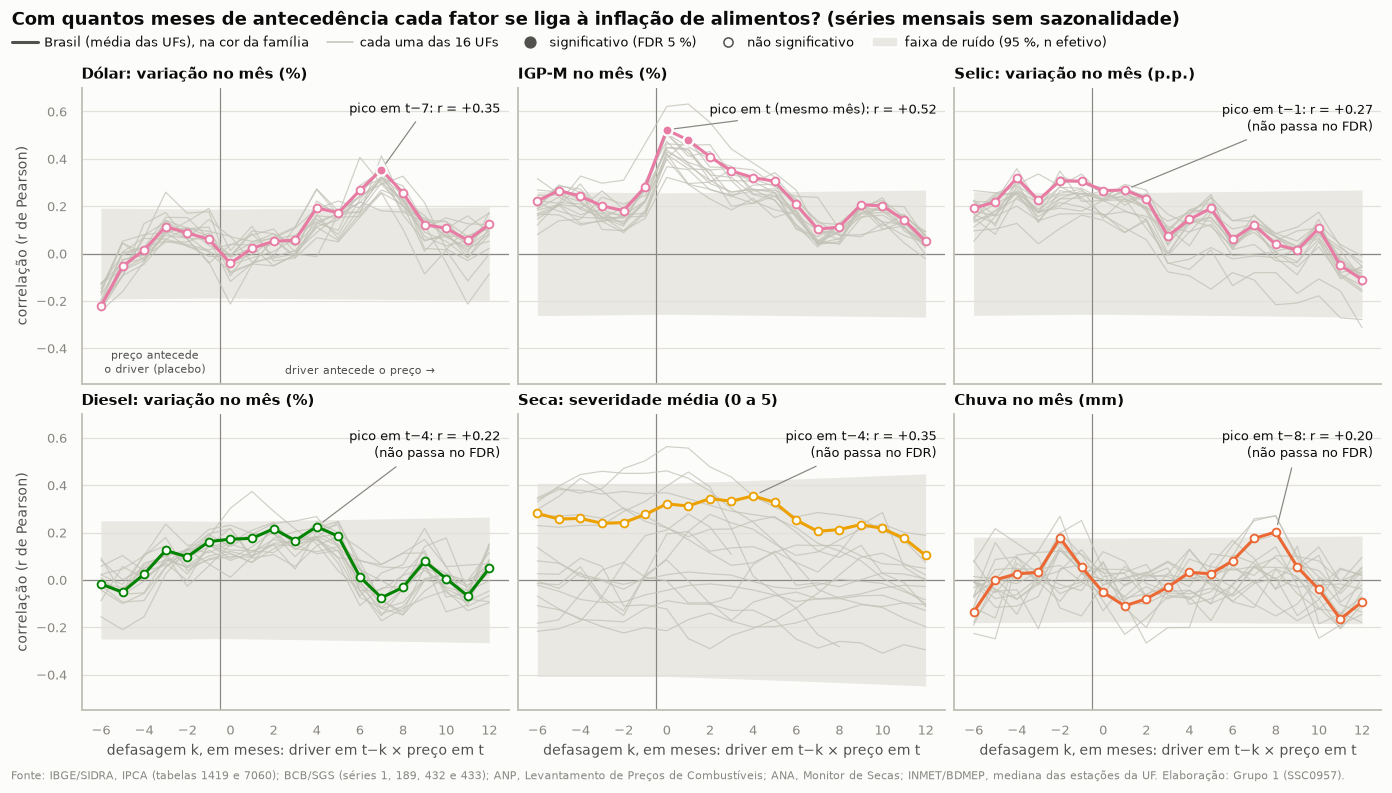

In [9]:
def largo(s):
    """Painel UF × mês em formato largo (meses nas linhas), para defasar pelo calendário."""
    return pd.DataFrame({"uf": fato["sigla_uf"], "mes": fato["ano_mes"], "v": s}).pivot(
        index="mes", columns="uf", values="v").reindex(MESES)


Y_UF = largo(A[ALVO])
PAINEIS = ["macro_dolar_var_mm", "macro_igpm", "macro_selic_delta",
           "comb_var_mm_diesel", "seca_severidade_media", "clima_chuva_mm_mes"]
todos = LAGS_PLACEBO + LAGS

fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.9), sharex=True, sharey=True, layout="constrained")
for ax, col in zip(axes.flat, PAINEIS):
    cor = CORES[DRIVERS.loc[col, "familia"]]
    c = CCF_NAC[CCF_NAC["driver"] == col].set_index("lag")
    rc = r_critico(c["n_ef"])
    ax.fill_between(c.index, -rc, rc, color="#e9e8e2", linewidth=0, zorder=0)
    ax.axhline(0, color=TINTA_3, linewidth=0.8, zorder=1)
    ax.axvline(-0.5, color=TINTA_3, linewidth=0.8, zorder=1)
    # Cada UF em cinza: o preço dela contra o driver dela (ou contra o driver nacional).
    X_UF = largo(A[col])
    for uf in ORDEM_UF:
        cu = ccf(X_UF[uf], Y_UF[uf], todos)["r"]
        ax.plot(cu.index, cu, color=NEUTRO, linewidth=0.8, alpha=0.75, zorder=2)
    ax.plot(c.index, c["r"], color=cor, linewidth=2, zorder=3)
    sig = (c["p_fdr"] < 0.05).to_numpy()
    ax.scatter(c.index[sig], c["r"][sig], s=44, color=cor, edgecolor=FUNDO, linewidth=1.5, zorder=5)
    ax.scatter(c.index[~sig], c["r"][~sig], s=26, facecolor=FUNDO, edgecolor=cor, linewidth=1.2, zorder=4)
    k = picos_nac.loc[col, "lag"]
    r = picos_nac.loc[col, "r"]
    passa = picos_nac.loc[col, "p_fdr"] < 0.05
    onde = em_t(k) + ("" if k else " (mesmo mês)")
    ax.annotate(f"pico em {onde}: r = {r:+.2f}" + ("" if passa else "\n(não passa no FDR)"),
                xy=(k, r), xytext=(0.98, 0.95), textcoords="axes fraction", ha="right", va="top", fontsize=8.5,
                arrowprops={"arrowstyle": "-", "color": TINTA_3, "linewidth": 0.8, "shrinkB": 5})
    ax.set_title(DRIVERS.loc[col, "rotulo"], fontsize=10)
    ax.set_xticks(range(-6, 13, 2))
    ax.grid(axis="x", visible=False)
axes[0, 0].text(-3.5, -0.52, "preço antecede\no driver (placebo)", ha="center", va="bottom", fontsize=7.5, color=TINTA_2)
axes[0, 0].text(6, -0.52, "driver antecede o preço →", ha="center", va="bottom", fontsize=7.5, color=TINTA_2)
axes[0, 0].set_ylim(-0.55, 0.7)
for ax in axes[:, 0]:
    ax.set_ylabel("correlação (r de Pearson)")
for ax in axes[1]:
    ax.set_xlabel("defasagem k, em meses: driver em t−k × preço em t")
legenda = [
    Line2D([], [], color=TINTA_2, linewidth=2, label="Brasil (média das UFs), na cor da família"),
    Line2D([], [], color=NEUTRO, linewidth=1, label="cada uma das 16 UFs"),
    Line2D([], [], marker="o", linestyle="", color=TINTA_2, markersize=7, label="significativo (FDR 5 %)"),
    Line2D([], [], marker="o", linestyle="", markerfacecolor=FUNDO, markeredgecolor=TINTA_2, markersize=6,
           label="não significativo"),
    Patch(facecolor="#e9e8e2", label="faixa de ruído (95 %, n efetivo)"),
]
# O título vai como título da legenda: assim o layout reserva espaço para os dois, sem sobreposição.
fig.legend(handles=legenda, loc="outside upper left", ncol=5, fontsize=8.5, handletextpad=0.5, columnspacing=1.4,
           alignment="left", title_fontproperties={"weight": "bold", "size": 11.5},
           title="Com quantos meses de antecedência cada fator se liga à inflação de alimentos? "
                 "(séries mensais sem sazonalidade)")
finalizar(fig, "fig_14_01_ccf_lags_otimos_drivers", "ipca", "macro", "comb", "seca", "clima")
plt.show()

**Leitura (`fig_14_01`):** a linha colorida é o Brasil; as linhas cinzas são as 16 UFs; o ponto cheio é o que passa
no FDR; a faixa clara é onde a correlação não se distingue de ruído.

- **IGP-M: transmissão no mesmo mês.** Pico em `t` (r = +0,52; Spearman +0,51), e `t−1` também passa (+0,48). A
  descida lenta até `t−5` é eco da autocorrelação do próprio IGP-M, como mostra o teste da Seção 1.3.
- **Dólar: 7 meses de atraso.** No mesmo mês a correlação é nula (−0,04). Ela sobe a partir de `t−4`, faz o pico em
  `t−7` (r = +0,35; Spearman +0,34) e desce. É o único ponto do dólar que passa no FDR, mas `t−6` e `t−8` (+0,26 e
  +0,25) desenham a mesma corcova: é um repasse distribuído, não um mês isolado.
- **Selic: causalidade invertida.** A correlação é positiva (juro sobe quando a comida sobe) e é **tão alta do lado
  placebo quanto do lado certo**: +0,32 em `t+4`, contra +0,27 em `t−1`. É o Banco Central reagindo à inflação, e
  não a Selic movendo o preço. Nada passa no FDR.
- **Diesel: sinal fraco e sem pico.** Um platô de +0,17 a +0,22 entre `t` e `t−5`, todo dentro da faixa de ruído
  (91 meses com dado, 60 efetivos).
- **Seca: alta em todos os lags, inclusive no placebo.** r entre +0,24 e +0,36 de `t+6` a `t−6`. Isso é a marca de
  uma série persistente que coincidiu com o ciclo de 2020-22, não de uma transmissão com data. São só 22 meses
  efetivos, e a faixa de ruído chega a ±0,42.
- **Chuva: em torno de zero.** O pico de +0,20 em `t−8` não passa no FDR nem tem mecanismo claro.

**As linhas cinzas respondem à pergunta regional antes da hora.** Para dólar e IGP-M, as 16 UFs desenham a mesma
curva: o choque macro chega igual em todo o país. Para a seca, as UFs se espalham de −0,3 a +0,5, sem padrão comum.

### 1.3 Dois testes de robustez

**(a) Pré-branqueamento (Box-Jenkins).** Um driver autocorrelacionado "espalha" a correlação pelos lags vizinhos.
Ajustamos um modelo AR ao driver, passamos o mesmo filtro no alvo e refazemos a CCF: sobra só o lag em que a
informação nova do driver encontra o preço.

**(b) Versão do alvo.** O plano pede o alvo relativo (`ipca_var_alimentacao_relativa`). Refazemos a CCF em três
versões do alvo para ver o que depende dessa escolha. A gasolina entra só aqui, como caso de controle.

In [10]:
def prebranquear(x, y, ordem_max=6):
    """Box-Jenkins: ajusta um AR ao driver (ordem por BIC) e passa o MESMO filtro nas duas séries."""
    d = pd.concat([x, y], axis=1, keys=["x", "y"]).dropna()
    ajustes = [AutoReg(d["x"].to_numpy(), lags=q).fit() for q in range(ordem_max + 1)]
    q = int(np.argmin([m.bic for m in ajustes]))
    phi = ajustes[q].params[1:]

    def filtra(s):
        v = s.to_numpy() - s.mean()
        out = v.copy()
        for j, f in enumerate(phi, 1):
            out[j:] -= f * v[:-j]
        out[:q] = np.nan
        return pd.Series(out, index=s.index)

    return filtra(d["x"]), filtra(d["y"]), q


linhas = []
for col in ["macro_dolar_var_mm", "macro_igpm", "macro_selic_delta", "macro_ipca_mm"]:
    xw, yw, q = prebranquear(NAC[col], NAC[ALVO])
    banda = 1.96 / np.sqrt(xw.notna().sum())
    rs = pd.Series({k: xw.shift(k).corr(yw) for k in LAGS_PLACEBO + LAGS})
    fora = [em_t(k) if k >= 0 else f"t+{-k}" for k in rs.index[rs.abs() > banda]]
    k0 = picos_nac.loc[col, "lag"]
    linhas.append(dict(driver=DRIVERS.loc[col, "rotulo"], ordem_AR=q, banda=banda, lag_otimo_original=k0,
                       r_original=picos_nac.loc[col, "r"], r_prebranqueado=rs[k0],
                       lags_fora_da_banda=", ".join(fora) or "nenhum"))
display(pd.DataFrame(linhas).set_index("driver").round(3))

# O mesmo teste em três versões do alvo: quanto o resultado depende da versão escolhida?
gasolina = serie_nacional(fato["comb_var_mm_gasolina"] - fato.groupby(["sigla_uf", "mes_cal"])["comb_var_mm_gasolina"].transform("mean"))
alvos = {
    "bruto (com sazonalidade)": serie_nacional(fato[ALVO]),
    "sem sazonalidade (principal)": NAC[ALVO],
    "relativo ao IPCA geral, sem sazonalidade": NAC["ipca_var_alimentacao_relativa"],
}
linhas = []
for col in [*PAINEIS, "gasolina"]:
    x = gasolina if col == "gasolina" else NAC[col]
    linha = {"driver": "Gasolina: variação no mês (%)" if col == "gasolina" else DRIVERS.loc[col, "rotulo"]}
    for nome, y in alvos.items():
        t = ccf(x, y)
        k = t["r"].abs().idxmax()
        linha[nome] = f"{t.loc[k, 'r']:+.2f} em {em_t(k)} (mesmo mês: {t.loc[0, 'r']:+.2f})"
    linhas.append(linha)
display(pd.DataFrame(linhas).set_index("driver"))

,ordem_AR,banda,lag_otimo_original,r_original,r_prebranqueado,lags_fora_da_banda
driver,,,,,,
Dólar: variação no mês (%),6,0.171,7,0.354,0.305,"t+6, t−6, t−7, t−8"
IGP-M no mês (%),1,0.167,0,0.523,0.394,t
Selic: variação no mês (p.p.),3,0.169,1,0.268,0.128,"t−3, t−10"
IPCA geral no mês (%),1,0.167,0,0.565,0.483,t


,bruto (com sazonalidade),sem sazonalidade (principal),"relativo ao IPCA geral, sem sazonalidade"
driver,,,
Dólar: variação no mês (%),+0.31 em t−7 (mesmo mês: -0.04),+0.35 em t−7 (mesmo mês: -0.04),+0.30 em t−7 (mesmo mês: +0.02)
IGP-M no mês (%),+0.46 em t (mesmo mês: +0.46),+0.52 em t (mesmo mês: +0.52),+0.38 em t (mesmo mês: +0.38)
Selic: variação no mês (p.p.),+0.23 em t (mesmo mês: +0.23),+0.27 em t−1 (mesmo mês: +0.27),+0.12 em t−5 (mesmo mês: +0.08)
Diesel: variação no mês (%),+0.23 em t−4 (mesmo mês: +0.14),+0.22 em t−4 (mesmo mês: +0.17),+0.26 em t−4 (mesmo mês: -0.12)
Seca: severidade média (0 a 5),+0.28 em t−5 (mesmo mês: +0.26),+0.35 em t−4 (mesmo mês: +0.32),+0.19 em t−3 (mesmo mês: +0.16)
Chuva no mês (mm),+0.17 em t−8 (mesmo mês: -0.05),+0.20 em t−8 (mesmo mês: -0.05),+0.25 em t−8 (mesmo mês: -0.02)
Gasolina: variação no mês (%),+0.21 em t−11 (mesmo mês: -0.09),+0.24 em t−11 (mesmo mês: -0.10),-0.48 em t (mesmo mês: -0.48)


**Leitura:**

- **IGP-M é contemporâneo.** Pré-branqueado, só o mesmo mês fica fora da banda (r = +0,39). Os lags de 1 a 5 da
  figura eram eco.
- **O atraso do dólar resiste.** `t−6`, `t−7` e `t−8` continuam fora da banda (r = +0,31 em `t−7`). Há também um
  ponto isolado do lado placebo (`t+6`); com 19 lags testados, um fora da banda de 95 % é o esperado por acaso.
- **A Selic não resiste.** No lag ótimo original, r cai de +0,27 para +0,13.
- **A versão do alvo não muda dólar nem IGP-M** (dólar: +0,31, +0,35 e +0,30 em `t−7`; IGP-M: +0,46, +0,52 e +0,38
  no mesmo mês).
- **Mas o alvo relativo cria um artefato com combustíveis.** A gasolina passa a ter r = **−0,48** no mesmo mês, e o
  diesel troca de sinal (+0,17 → −0,12). Não é economia: a gasolina está **dentro** do IPCA geral que o alvo
  relativo subtrai. Quando ela sobe, o IPCA geral sobe e a comida "relativa" cai, por aritmética.

> **Encaminhamento para a modelagem (T-041):** não usar `ipca_var_alimentacao_relativa` como alvo em modelos que
> tenham combustíveis entre as variáveis. Para isolar o regional, usar o alvo menos a média das UFs no mês.

## 2. Padrões em extremos & caudas

> **Objetivo:** olhar a matriz completa (todos os drivers × todos os lags × as duas camadas), localizar onde a
> transmissão é extrema e onde é nula, e testar se a relação muda nas caudas dos drivers.

### 2.1 A matriz completa de correlação com defasagens

Para a camada regional, a correlação é calculada no painel UF × mês, com as duas séries já sem a média do mês. O
p-valor usa o erro-padrão de **Driscoll-Kraay**, robusto às duas dependências do painel: UFs que se movem juntas e
autocorrelação de até 6 meses. As defasagens de 1 a 12 meses vêm de `adicionar_lags_painel` (`eda_utils.py`).

figura salva: outputs/figuras/eda/fig_14_02_matriz_correlacao_com_lags.png


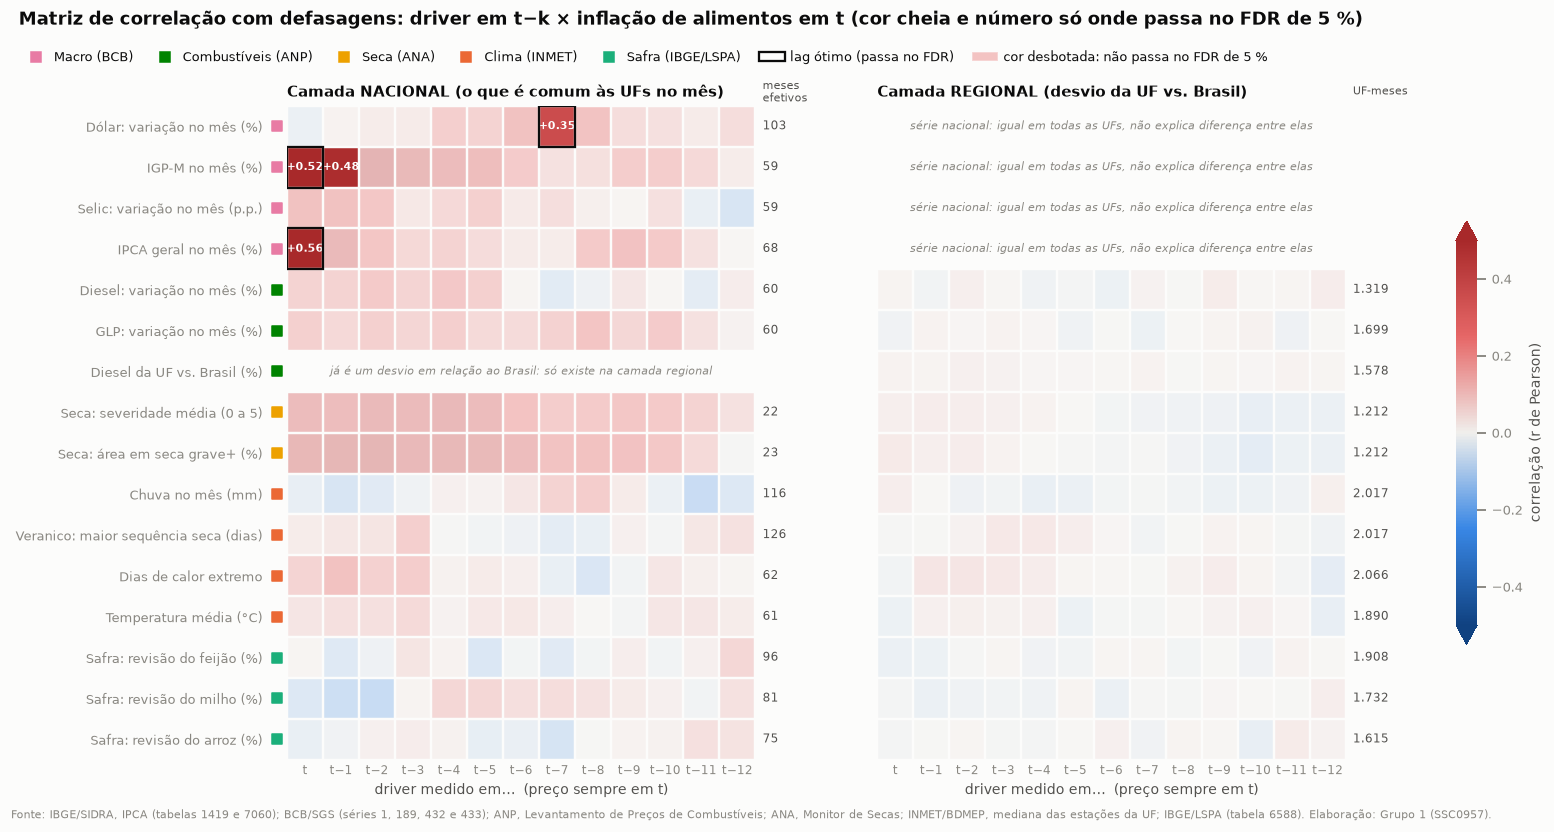

Camada nacional: 4 de 195 células passam no FDR.  Camada regional: 0 de 156.
Maior |r| na camada regional: 0.084  →  r² = 0.7 % da variância regional.


,lag,r,r_lag0,n,p,p_fdr
driver,,,,,,
Diesel: variação no mês (%),9,0.052,0.019,1319,0.006,0.188
GLP: variação no mês (%),7,-0.036,-0.026,1699,0.040,0.477
Diesel da UF vs. Brasil (%),2,0.033,0.021,1578,0.117,0.527
Seca: severidade média (0 a 5),10,-0.053,0.040,1212,0.058,0.527
Seca: área em seca grave+ (%),10,-0.068,0.059,1212,0.014,0.314
Chuva no mês (mm),4,-0.047,0.045,2017,0.094,0.527
Veranico: maior sequência seca (dias),4,0.068,-0.006,2017,0.031,0.435
Dias de calor extremo,1,0.084,-0.020,2066,0.001,0.083
Temperatura média (°C),12,-0.053,-0.038,1890,0.054,0.527


In [11]:
# ---- Camada regional: painel UF × mês, depois de tirar a média do mês das duas séries ------------
PAINEL = pd.concat([fato[["sigla_uf", "ano_mes"]], R.add_suffix("_r")], axis=1)
PAINEL["t"] = fato["ano_mes"].astype("int64") - fato["ano_mes"].astype("int64").min()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", PerformanceWarning)
    # lags de 1 a 12 meses, por UF, pelo utilitário compartilhado do grupo
    PAINEL = adicionar_lags_painel(PAINEL, [c + "_r" for c in DRIVERS_UF], lags=list(range(1, 13))).copy()


def ccf_regional(xcol, ycol, lags=LAGS, maxlags=6):
    """Correlação em painel na camada regional, com erro-padrão de Driscoll-Kraay.

    Driscoll-Kraay é robusto às duas dependências do painel: UFs que se movem juntas no
    mesmo mês e autocorrelação de até `maxlags` meses. Com as séries padronizadas, o
    coeficiente da regressão simples é o próprio r de Pearson.
    """
    linhas = []
    for k in lags:
        xk = f"{xcol}_r" if k == 0 else f"{xcol}_r_lag{k}"
        d = PAINEL[[xk, f"{ycol}_r", "t"]].dropna()
        z = (d.iloc[:, :2] - d.iloc[:, :2].mean()) / d.iloc[:, :2].std()
        fit = sm.OLS(z.iloc[:, 1].to_numpy(), sm.add_constant(z.iloc[:, 0].to_numpy())).fit(
            cov_type="hac-groupsum", cov_kwds={"time": d["t"].to_numpy(), "maxlags": maxlags})
        linhas.append((k, fit.params[1], len(d), fit.pvalues[1]))
    return pd.DataFrame(linhas, columns=["lag", "r", "n", "p"]).set_index("lag")


CCF_REG = pd.concat([ccf_regional(c, ALVO).assign(driver=c).reset_index() for c in DRIVERS_UF], ignore_index=True)
CCF_REG["p_fdr"] = fdr(CCF_REG["p"])
picos_reg = pico(CCF_REG).loc[DRIVERS_UF]


def pintar(valores, forte, vlim, fraco=0.38):
    """Cor pela correlação; o que não tem evidência fica desbotado (a cor recua, o valor não some)."""
    rgba = DIVERGENTE(plt.Normalize(-vlim, vlim)(np.nan_to_num(valores)))
    rgba[..., 3] = np.where(np.isnan(valores), 0.0, np.where(forte, 1.0, fraco))
    return rgba


def barra_de_cor(fig, eixos, vlim, rotulo, **kw):
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(-vlim, vlim), DIVERGENTE), ax=eixos, extend="both", **kw)
    cb.set_label(rotulo)
    cb.outline.set_visible(False)
    return cb


def desenhar_matriz(ax, tabela, linhas, colunas, rotulos, vlim=0.5, vazio=None):
    """Heatmap driver × lag: cor cheia e número só onde passa no FDR; moldura no lag ótimo que passa."""
    M = tabela.pivot(index="driver", columns="lag", values="r").reindex(index=linhas, columns=colunas)
    P = tabela.pivot(index="driver", columns="lag", values="p_fdr").reindex(index=linhas, columns=colunas)
    im = ax.imshow(pintar(M.to_numpy(), (P < 0.05).to_numpy(), vlim), aspect="auto")
    for i, lin in enumerate(linhas):
        if M.loc[lin].isna().all():
            if vazio:
                ax.text(len(colunas) / 2 - 0.5, i, vazio, ha="center", va="center", fontsize=7.5, color=TINTA_3,
                        style="italic")
            continue
        for j, k in enumerate(colunas):
            v, p = M.loc[lin, k], P.loc[lin, k]
            if pd.notna(p) and p < 0.05:
                ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7.2, fontweight="bold",
                        color="#ffffff" if abs(v) > 0.33 else TINTA)
        kmax = M.loc[lin].abs().idxmax()
        if P.loc[lin, kmax] < 0.05:
            ax.add_patch(Rectangle((colunas.index(kmax) - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=TINTA,
                                   linewidth=1.5, zorder=5))
    ax.set_xticks(range(len(colunas)), ["t"] + [f"t−{k}" for k in colunas[1:]], fontsize=7.8)
    ax.set_yticks(range(len(linhas)), rotulos, fontsize=8.5)
    ax.tick_params(length=0)
    ax.tick_params(axis="y", pad=16)
    ax.set_xticks(np.arange(-0.5, len(colunas)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(linhas)), minor=True)
    ax.grid(False)
    ax.grid(which="minor", color=FUNDO, linewidth=1.6)
    ax.tick_params(which="minor", length=0)
    for s in ax.spines.values():
        s.set_visible(False)


def fichas_de_familia(ax, familias):
    """Quadradinho na cor da família ao lado do rótulo (o texto fica sempre em tinta)."""
    for i, fam in enumerate(familias):
        ax.scatter(-0.022, i, marker="s", s=42, color=CORES[fam], transform=ax.get_yaxis_transform(),
                   clip_on=False, zorder=6)


linhas_m = DRIVERS.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 6.6), sharey=True, layout="constrained")
desenhar_matriz(axes[0], CCF_NAC, linhas_m, LAGS, DRIVERS["rotulo"].tolist(),
                vazio="já é um desvio em relação ao Brasil: só existe na camada regional")
desenhar_matriz(axes[1], CCF_REG, linhas_m, LAGS, DRIVERS["rotulo"].tolist(),
                vazio="série nacional: igual em todas as UFs, não explica diferença entre elas")
fichas_de_familia(axes[0], DRIVERS["familia"])
axes[0].set_title("Camada NACIONAL (o que é comum às UFs no mês)", fontsize=10)
axes[1].set_title("Camada REGIONAL (desvio da UF vs. Brasil)", fontsize=10)
# Ao lado de cada linha, quantos meses independentes sustentam a correlação (n efetivo no lag ótimo).
axes[0].text(len(LAGS) - 0.3, -0.85, "meses\nefetivos", ha="left", va="center", fontsize=7.5, color=TINTA_2, linespacing=0.95)
for i, lin in enumerate(linhas_m):
    if lin in picos_nac.index:
        axes[0].text(len(LAGS) - 0.3, i, f"{picos_nac.loc[lin, 'n_ef']:.0f}", ha="left", va="center", fontsize=8, color=TINTA_2)
axes[1].text(len(LAGS) - 0.3, -0.85, "UF-meses", ha="left", va="center", fontsize=7.5, color=TINTA_2)
for i, lin in enumerate(linhas_m):
    if lin in picos_reg.index:
        axes[1].text(len(LAGS) - 0.3, i, f"{picos_reg.loc[lin, 'n']:,.0f}".replace(",", "."), ha="left", va="center",
                     fontsize=8, color=TINTA_2)
for ax in axes:
    ax.set_xlabel("driver medido em…  (preço sempre em t)")
fig.get_layout_engine().set(wspace=0.09)
barra_de_cor(fig, axes, 0.5, "correlação (r de Pearson)", fraction=0.02, pad=0.045)
fam_legenda = [Line2D([], [], marker="s", linestyle="", color=CORES[f], markersize=7, label=NOME_FAMILIA[f])
               for f in NOME_FAMILIA]
fam_legenda.append(Patch(facecolor="none", edgecolor=TINTA, linewidth=1.5, label="lag ótimo (passa no FDR)"))
fam_legenda.append(Patch(facecolor="#e66767", alpha=0.38, label="cor desbotada: não passa no FDR de 5 %"))
fig.legend(handles=fam_legenda, loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=7, fontsize=8.5, handletextpad=0.4,
           columnspacing=1.4)
fig.suptitle("Matriz de correlação com defasagens: driver em t−k × inflação de alimentos em t "
             "(cor cheia e número só onde passa no FDR de 5 %)", x=0.005, y=1.09, ha="left", fontweight="bold",
             fontsize=11.5)
finalizar(fig, "fig_14_02_matriz_correlacao_com_lags", "ipca", "macro", "comb", "seca", "clima", "safra")
plt.show()

print(f"Camada nacional: {int((CCF_NAC.query('lag >= 0')['p_fdr'] < 0.05).sum())} de {CCF_NAC.query('lag >= 0')['p'].notna().sum()} "
      f"células passam no FDR.  Camada regional: {int((CCF_REG['p_fdr'] < 0.05).sum())} de {CCF_REG['p'].notna().sum()}.")
print(f"Maior |r| na camada regional: {CCF_REG['r'].abs().max():.3f}  →  r² = {CCF_REG['r'].abs().max() ** 2 * 100:.1f} % da variância regional.")
display(picos_reg.assign(driver=lambda d: DRIVERS.loc[d.index, "rotulo"].values)
        .set_index("driver")[["lag", "r", "r_lag0", "n", "p", "p_fdr"]].round(3))

**Leitura (`fig_14_02`):** cor cheia e número só onde a célula passa no FDR; o resto fica desbotado. A coluna à
direita de cada painel diz quanto dado sustenta a linha.

**Camada nacional (esquerda): 4 células em 195.**

- IGP-M em `t` e `t−1`, IPCA geral em `t` e dólar em `t−7`. O IPCA geral no mesmo mês é em parte mecânico: a
  comida é um dos seus componentes.
- **Seca:** são as linhas mais quentes entre as desbotadas (r de +0,3 a +0,4), sustentadas por 22 meses efetivos.
  É **falta de dado, não evidência de ausência**: a série nacional só existe de 2020-08 em diante e passa quase
  toda dentro do ciclo de 2020-22.
- **Clima:** calor extremo em `t−1` (r = +0,26; Spearman +0,36) e veranico em `t−3` (+0,19) têm p nominal entre
  0,03 e 0,04, mas não passam no FDR. São os melhores candidatos climáticos na camada nacional.
- **Safra:** |r| ≤ 0,17 e sem padrão entre lags vizinhos. A defasagem não resgata a revisão de safra.

**Camada regional (direita): nenhuma célula em 156.**

- O maior |r| é **0,084** (dias de calor extremo, 1 mês antes): explica **0,7 %** da variância regional.
- O diesel da UF em relação ao Brasil, a única variável espacial de custo da tabela, fica em |r| ≤ 0,03 em todos os
  lags.

> **Achado central.** Os drivers locais da tabela (clima da capital, seca da UF, safra da UF, combustível da UF) não
> explicam por que a comida sobe mais numa UF do que em outra no mesmo mês. Isso não quer dizer que clima e safra
> não importem: quer dizer que **o clima e a safra do lugar onde se consome não são os do lugar onde se produz**. É
> o argumento empírico a favor do T-022 (clima e safra ponderados pela região produtora).

### 2.2 Onde a transmissão é extrema e onde é nula: os 16 itens

O grupo Alimentação é uma média, e médias escondem extremos. Repetimos a busca do lag ótimo para cada item contra
oito drivers. Como cada par escolhe o melhor entre 13 lags, o p-valor é multiplicado por 13 (Bonferroni) antes do
FDR. A célula também grava `outputs/tabelas/lags_otimos.csv`, o insumo que o T-031 deve ao T-041.

figura salva: outputs/figuras/eda/fig_14_05_subitens_lag_otimo.png


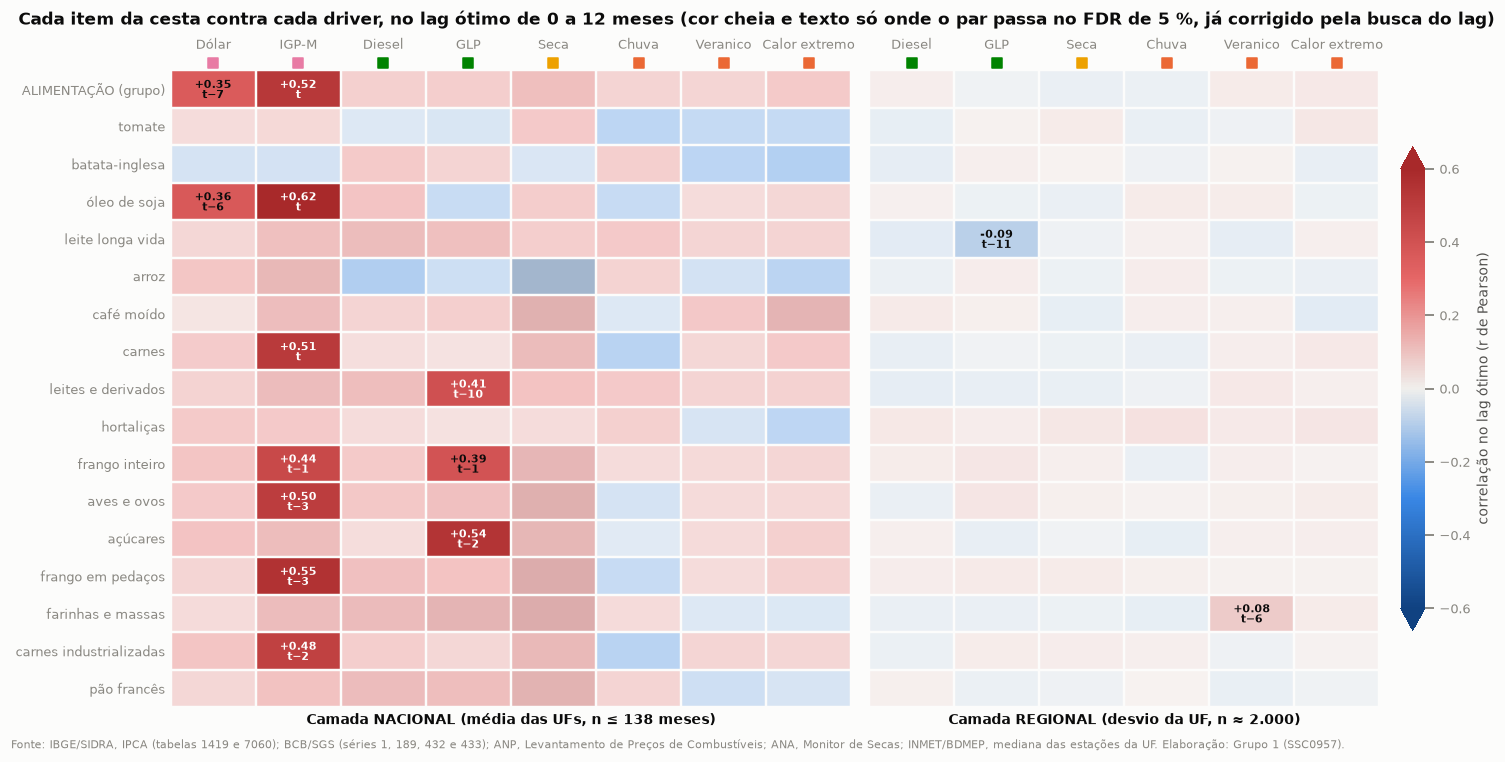


Camada nacional: 12 de 136 pares passam no FDR. Os mais fortes:


,alvo,driver,lag,r,n,p_fdr
43,óleo de soja,IGP-M no mês (%),0,0.619,138,0.000
183,frango em pedaços,IGP-M no mês (%),3,0.550,135,0.010
171,açúcares,GLP: variação no mês (%),2,0.542,116,0.016
1,ALIMENTAÇÃO (grupo),IGP-M no mês (%),0,0.523,138,0.010
99,carnes,IGP-M no mês (%),0,0.512,138,0.002
155,aves e ovos,IGP-M no mês (%),3,0.498,135,0.011
211,carnes industrializadas,IGP-M no mês (%),2,0.479,136,0.028
141,frango inteiro,IGP-M no mês (%),1,0.444,137,0.015
115,leites e derivados,GLP: variação no mês (%),10,0.406,108,0.037
143,frango inteiro,GLP: variação no mês (%),1,0.390,117,0.042



Camada regional: 2 de 102 pares passam no FDR. Os mais fortes:


,alvo,driver,lag,r,n,p_fdr
65,leite longa vida,GLP: variação no mês (%),11,-0.089,1635,0.003
208,farinhas e massas,Veranico: maior sequência seca (dias),6,0.079,1985,0.003



251 pares driver × alvo → outputs/tabelas/lags_otimos.csv


In [12]:
# ---- Os mesmos drivers contra os 16 itens: lag ótimo de cada par --------------------------------
DRV_ITENS = ["macro_dolar_var_mm", "macro_igpm", "comb_var_mm_diesel", "comb_var_mm_glp_13kg",
             "seca_severidade_media", "clima_chuva_mm_mes", "clima_max_dias_secos_seguidos", "clima_dias_calor_extremo"]
DRV_ITENS_UF = [c for c in DRV_ITENS if c in DRIVERS_UF]
ORDEM_ITENS = [ALVO] + sorted([c for c in ITENS if c != ALVO], key=lambda c: -NAC[c].std())


def pico_com_busca(t):
    """Lag ótimo e p-valor corrigido pela busca em 13 lags (Bonferroni dentro do par)."""
    k = t["r"].abs().idxmax()
    return dict(lag=k, r=t.loc[k, "r"], n=t.loc[k, "n"], p=min(1.0, t.loc[k, "p"] * len(t)))


linhas = []
for item in ORDEM_ITENS:
    for col in DRV_ITENS:
        linhas.append(dict(camada="nacional", alvo=item, driver=col, **pico_com_busca(ccf(NAC[col], NAC[item]))))
    for col in DRV_ITENS_UF:
        linhas.append(dict(camada="regional", alvo=item, driver=col, **pico_com_busca(ccf_regional(col, item))))
SUB = pd.DataFrame(linhas)
SUB["p_fdr"] = SUB.groupby("camada")["p"].transform(fdr)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.6), sharey=True, layout="constrained",
                         gridspec_kw={"width_ratios": [len(DRV_ITENS), len(DRV_ITENS_UF)]})
curto = lambda c: DRIVERS.loc[c, "rotulo"].split(":")[0].split(" (")[0].replace("Dias de calor", "Calor").replace(" no mês", "")
for ax, camada, cols in zip(axes, ["nacional", "regional"], [DRV_ITENS, DRV_ITENS_UF]):
    s = SUB[SUB["camada"] == camada]
    M = s.pivot(index="alvo", columns="driver", values="r").loc[ORDEM_ITENS, cols]
    K = s.pivot(index="alvo", columns="driver", values="lag").loc[ORDEM_ITENS, cols]
    P = s.pivot(index="alvo", columns="driver", values="p_fdr").loc[ORDEM_ITENS, cols]
    ax.imshow(pintar(M.to_numpy(), (P < 0.05).to_numpy(), 0.6), aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if P.iat[i, j] < 0.05:
                ax.text(j, i, f"{M.iat[i, j]:+.2f}\n{em_t(K.iat[i, j])}", ha="center", va="center", fontsize=7,
                        fontweight="bold", color="#ffffff" if abs(M.iat[i, j]) > 0.4 else TINTA, linespacing=0.95)
    ax.set_xticks(range(len(cols)), [curto(c) for c in cols], fontsize=8.5)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(ORDEM_ITENS)), [NOME_ITEM[c] for c in ORDEM_ITENS], fontsize=8.5)
    ax.tick_params(length=0)
    ax.tick_params(axis="x", pad=12)
    ax.set_xticks(np.arange(-0.5, len(cols)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(ORDEM_ITENS)), minor=True)
    ax.grid(False)
    ax.grid(which="minor", color=FUNDO, linewidth=1.6)
    ax.tick_params(which="minor", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    for j, c in enumerate(cols):
        ax.scatter(j, 1.012, marker="s", s=36, color=CORES[DRIVERS.loc[c, "familia"]],
                   transform=ax.get_xaxis_transform(), clip_on=False, zorder=6)
axes[0].set_xlabel("Camada NACIONAL (média das UFs, n ≤ 138 meses)", fontweight="bold", color=TINTA)
axes[1].set_xlabel("Camada REGIONAL (desvio da UF, n ≈ 2.000)", fontweight="bold", color=TINTA)
barra_de_cor(fig, axes, 0.6, "correlação no lag ótimo (r de Pearson)", fraction=0.02, pad=0.015)
fig.suptitle("Cada item da cesta contra cada driver, no lag ótimo de 0 a 12 meses "
             "(cor cheia e texto só onde o par passa no FDR de 5 %, já corrigido pela busca do lag)",
             x=0.005, ha="left", fontweight="bold", fontsize=11)
finalizar(fig, "fig_14_05_subitens_lag_otimo", "ipca", "macro", "comb", "seca", "clima")
plt.show()

for camada in ["nacional", "regional"]:
    s = SUB[(SUB["camada"] == camada) & (SUB["p_fdr"] < 0.05)]
    print(f"\nCamada {camada}: {len(s)} de {(SUB['camada'] == camada).sum()} pares passam no FDR. Os mais fortes:")
    display(s.assign(alvo=s["alvo"].map(NOME_ITEM), driver=s["driver"].map(DRIVERS["rotulo"]), abs_r=s["r"].abs())
            .sort_values("abs_r", ascending=False).head(10)[["alvo", "driver", "lag", "r", "n", "p_fdr"]].round(3))

# ---- Tabela de lags ótimos: insumo declarado da modelagem (T-031 → T-041) ------------------------
lags_otimos = pd.concat([
    picos_nac.reset_index().assign(camada="nacional", alvo=ALVO),
    picos_reg.reset_index().assign(camada="regional", alvo=ALVO),
    SUB[SUB["alvo"] != ALVO].assign(nota="p já multiplicado por 13 (busca do lag)"),
], ignore_index=True)
lags_otimos["familia"] = lags_otimos["driver"].map(DRIVERS["familia"])
lags_otimos["driver_rotulo"] = lags_otimos["driver"].map(DRIVERS["rotulo"])
lags_otimos["passa_fdr_5pct"] = lags_otimos["p_fdr"] < 0.05
lags_otimos = lags_otimos.rename(columns={"lag": "lag_otimo_meses", "rho": "rho_spearman", "n_ef": "n_efetivo"})[
    ["camada", "alvo", "driver", "driver_rotulo", "familia", "lag_otimo_meses", "r", "rho_spearman", "r_lag0", "n",
     "n_efetivo", "p", "p_fdr", "passa_fdr_5pct", "nota"]]
lags_otimos.to_csv(TABELAS / "lags_otimos.csv", index=False, float_format="%.4f")
print(f"\n{len(lags_otimos)} pares driver × alvo → {(TABELAS / 'lags_otimos.csv').relative_to(RAIZ)}")

**Leitura (`fig_14_05`):** os itens estão ordenados do mais volátil (tomate) ao menos volátil (pão francês).

**Onde a transmissão é extrema: a cadeia dos grãos.** Na camada nacional passam 12 pares em 136, e 7 são do IGP-M
(o grupo e seis itens):

- **óleo de soja** (r = +0,62, no mesmo mês) e **carnes** (+0,51, no mesmo mês);
- **frango em pedaços** (+0,55), **aves e ovos** (+0,50), **carnes industrializadas** (+0,48) e **frango inteiro**
  (+0,44), com **1 a 3 meses de atraso**.

É a sequência que se espera do custo: soja e milho sobem no atacado, o óleo acompanha na hora e a proteína animal,
que come ração, acompanha depois.

**O dólar**, fora o grupo, só passa no óleo de soja (+0,36 em `t−6`). Nos demais itens o r é menor (até +0,30) e
não passa individualmente, mas o **lag coincide**: é `t−7` ou `t−8` em **10 dos 16 itens** e `t−6` em mais dois.
Ruído não escolheria o mesmo lag tantas vezes.

**Uma relação não óbvia:** GLP × açúcares (+0,54 em `t−2`), frango inteiro (+0,39 em `t−1`) e leites e derivados
(+0,41 em `t−10`). Não há canal direto do gás de cozinha para o açúcar. A hipótese mais simples é um terceiro
fator: os reajustes de combustíveis, que movem o GLP e também o etanol, concorrente do açúcar na usina. Fica
registrada como relação a investigar, não como causa.

**Onde a transmissão é nula: os perecíveis.** Para tomate, batata-inglesa e hortaliças **nenhum** dos oito drivers
passa (|r| ≤ 0,29). Tomate e batata são, de longe, os itens mais voláteis da cesta (desvio de 12 e 11 p.p. por mês
na média das UFs, contra 0,7 do grupo), e são os menos explicados pela tabela.

**Dois sinais fortes que não passam, e por quê:**

- **Café × calor extremo 9 meses antes: r = +0,49.** É o maior sinal climático da matriz. Não passa porque o preço
  do café é muito persistente (poucos meses efetivos). Fica como candidato para o caso do café (Frentes 1 e 2).
- **Coluna da seca:** r de até +0,65 (frango em pedaços) e −0,62 (arroz), todos desbotados. São ~70 meses dentro do
  ciclo de 2020-22.

**Camada regional:** passam 2 pares em 102, com |r| < 0,09 e lags de 11 e 6 meses sem mecanismo. São falsos
positivos prováveis. O par mais plausível, **hortaliças × chuva local 1 mês antes** (r = +0,12), não passa na
correção.

### 2.3 A relação muda nas caudas?

A correlação resume a relação em um número e supõe que ela é a mesma no meio e nas pontas. Aqui cada driver é
cortado em cinco faixas pelos próprios percentis, com as duas caudas (≤ P10 e > P90) separadas, e medimos a
inflação de alimentos média em cada faixa.

figura salva: outputs/figuras/eda/fig_14_06_resposta_em_extremos.png


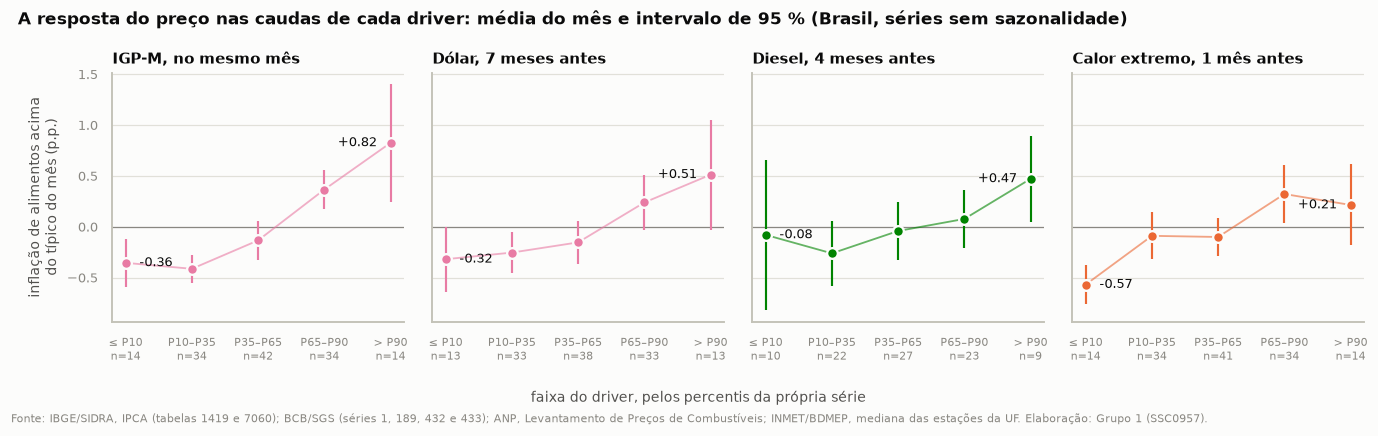

Base de comparação das duas últimas colunas: 20 % (o driver está no quinto superior em 1 a cada 5 meses).


,lag,r,rho,resposta_no_P90,resposta_no_P10,razao_alta_queda,pct_picos_do_preco_com_driver_alto,pct_vales_do_preco_com_driver_alto
driver,,,,,,,,
IGP-M no mês (%),0,0.52,0.51,0.82,-0.36,2.32,57.14,0.00
Dólar: variação no mês (%),7,0.35,0.34,0.51,-0.32,1.60,30.77,0.00
Diesel: variação no mês (%),4,0.22,0.32,0.47,-0.08,5.82,33.33,0.00
Dias de calor extremo,1,0.26,0.36,0.21,-0.57,0.37,35.71,14.29


In [13]:
# ---- A relação é a mesma nas caudas? Resposta do preço por faixa do driver ----------------------
FAIXAS = ["≤ P10", "P10–P35", "P35–P65", "P65–P90", "> P90"]
EXTREMOS = [
    ("macro_igpm", 0), ("macro_dolar_var_mm", 7), ("comb_var_mm_diesel", int(picos_nac.loc["comb_var_mm_diesel", "lag"])),
    ("clima_dias_calor_extremo", int(picos_nac.loc["clima_dias_calor_extremo", "lag"])),
]
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.7), sharey=True)
resumo = []
for ax, (col, k) in zip(axes, EXTREMOS):
    d = pd.concat([NAC[col].shift(k), NAC[ALVO]], axis=1, keys=["x", "y"]).dropna()
    cortes = d["x"].quantile([0.10, 0.35, 0.65, 0.90]).to_numpy()
    d["faixa"] = pd.cut(d["x"], [-np.inf, *cortes, np.inf], labels=FAIXAS)
    g = d.groupby("faixa", observed=True)["y"].agg(["mean", "sem", "size"])
    ic = g["sem"] * stats.t.ppf(0.975, g["size"] - 1)
    cor = CORES[DRIVERS.loc[col, "familia"]]
    ax.axhline(0, color=TINTA_3, linewidth=0.8)
    ax.plot(range(5), g["mean"], color=cor, linewidth=1.2, alpha=0.6, zorder=2)
    ax.errorbar(range(5), g["mean"], yerr=ic, fmt="o", color=cor, markersize=7, markeredgecolor=FUNDO,
                markeredgewidth=1.5, elinewidth=1.4, capsize=0, zorder=3)
    for i in (0, 4):
        ax.annotate(f"{g['mean'].iloc[i]:+.2f}", (i, g["mean"].iloc[i]), xytext=(9 if i == 0 else -9, 0),
                    textcoords="offset points", ha="left" if i == 0 else "right", va="center", fontsize=8.5)
    ax.set_xticks(range(5), [f"{f}\nn={n}" for f, n in zip(FAIXAS, g["size"])], fontsize=7.5)
    quando = "no mesmo mês" if k == 0 else ("1 mês antes" if k == 1 else f"{k} meses antes")
    ax.set_title(f"{curto(col)}, {quando}", fontsize=9.5)
    ax.grid(axis="x", visible=False)
    alta, queda = g["mean"].iloc[4], g["mean"].iloc[0]
    topo, base = NAC[ALVO] >= NAC[ALVO].quantile(0.9), NAC[ALVO] <= NAC[ALVO].quantile(0.1)
    forte = (NAC[col].shift(k) >= NAC[col].shift(k).quantile(0.8)).where(NAC[col].shift(k).notna())
    resumo.append(dict(driver=DRIVERS.loc[col, "rotulo"], lag=k, r=d["x"].corr(d["y"]), rho=stats.spearmanr(d["x"], d["y"]).statistic,
                       resposta_no_P90=alta, resposta_no_P10=queda, razao_alta_queda=abs(alta / queda),
                       pct_picos_do_preco_com_driver_alto=forte[topo].mean() * 100,
                       pct_vales_do_preco_com_driver_alto=forte[base].mean() * 100))
axes[0].set_ylabel("inflação de alimentos acima\ndo típico do mês (p.p.)")
fig.supxlabel("faixa do driver, pelos percentis da própria série", fontsize=9, color=TINTA_2)
fig.suptitle("A resposta do preço nas caudas de cada driver: média do mês e intervalo de 95 % (Brasil, séries sem sazonalidade)",
             x=0.005, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout()
finalizar(fig, "fig_14_06_resposta_em_extremos", "ipca", "macro", "comb", "clima")
plt.show()
print("Base de comparação das duas últimas colunas: 20 % (o driver está no quinto superior em 1 a cada 5 meses).")
display(pd.DataFrame(resumo).set_index("driver").round(2))

**Leitura (`fig_14_06`):**

- **IGP-M: a resposta é convexa.** Nos 10 % de meses com IGP-M mais alto, a comida sobe **+0,82 p.p.** acima do
  típico; nos 10 % mais baixos, cai só −0,36 p.p. A alta repassa 2,3 vezes mais que a queda.
- **Dólar (7 meses antes): mesma assimetria, mais suave.** +0,51 p.p. depois das maiores desvalorizações, −0,32
  depois das maiores valorizações (razão 1,6).
- **Os picos do preço têm assinatura; os vales, não.** Dos meses no décimo superior da inflação de alimentos,
  **57 %** tiveram IGP-M no quinto superior (o acaso daria 20 %), e 31 % vieram 7 meses depois de um dólar no quinto
  superior. Dos meses no décimo inferior, **nenhum** teve driver alto.
- **Diesel:** +0,47 p.p. na cauda de cima, mas com 9 meses e intervalo largo; a curva não é monótona.
- **Calor extremo (1 mês antes): a assimetria é inversa.** O efeito mais nítido é o de meses **mais frescos** que o
  normal (−0,57 p.p.), não o de meses mais quentes (+0,21).

A assimetria de IGP-M e dólar combina com o achado 4 do notebook 09 (73 choques de alta contra 15 de queda) e vai
na direção da **H3** da proposta (a alta chega rápido, a queda demora), agora medida no câmbio e no atacado, não no
clima.

**Cautela:** cada cauda tem de 9 a 14 meses, e meses vizinhos não são independentes (2015 e 2020 concentram as
grandes desvalorizações). Os intervalos são indicativos.

## 3. Casos especiais & quebras estruturais

> **Objetivo:** olhar os grandes choques macro (o câmbio de 2015 e de 2020, os ciclos da Selic, o IGP-M de 2020-21)
> e responder à pergunta que decide se "lag ótimo" é uma constante: **a transmissão é a mesma em todos os
> períodos?**

### 3.1 Os choques e a estabilidade da transmissão

Quatro painéis com o mesmo eixo de tempo. Os três primeiros são as séries; o último é a correlação recalculada em
janelas móveis de 36 meses para os dois pares que passaram no FDR. As faixas cinzas são os episódios do plano.

figura salva: outputs/figuras/eda/fig_14_03_choques_macro_dolar_selic.png


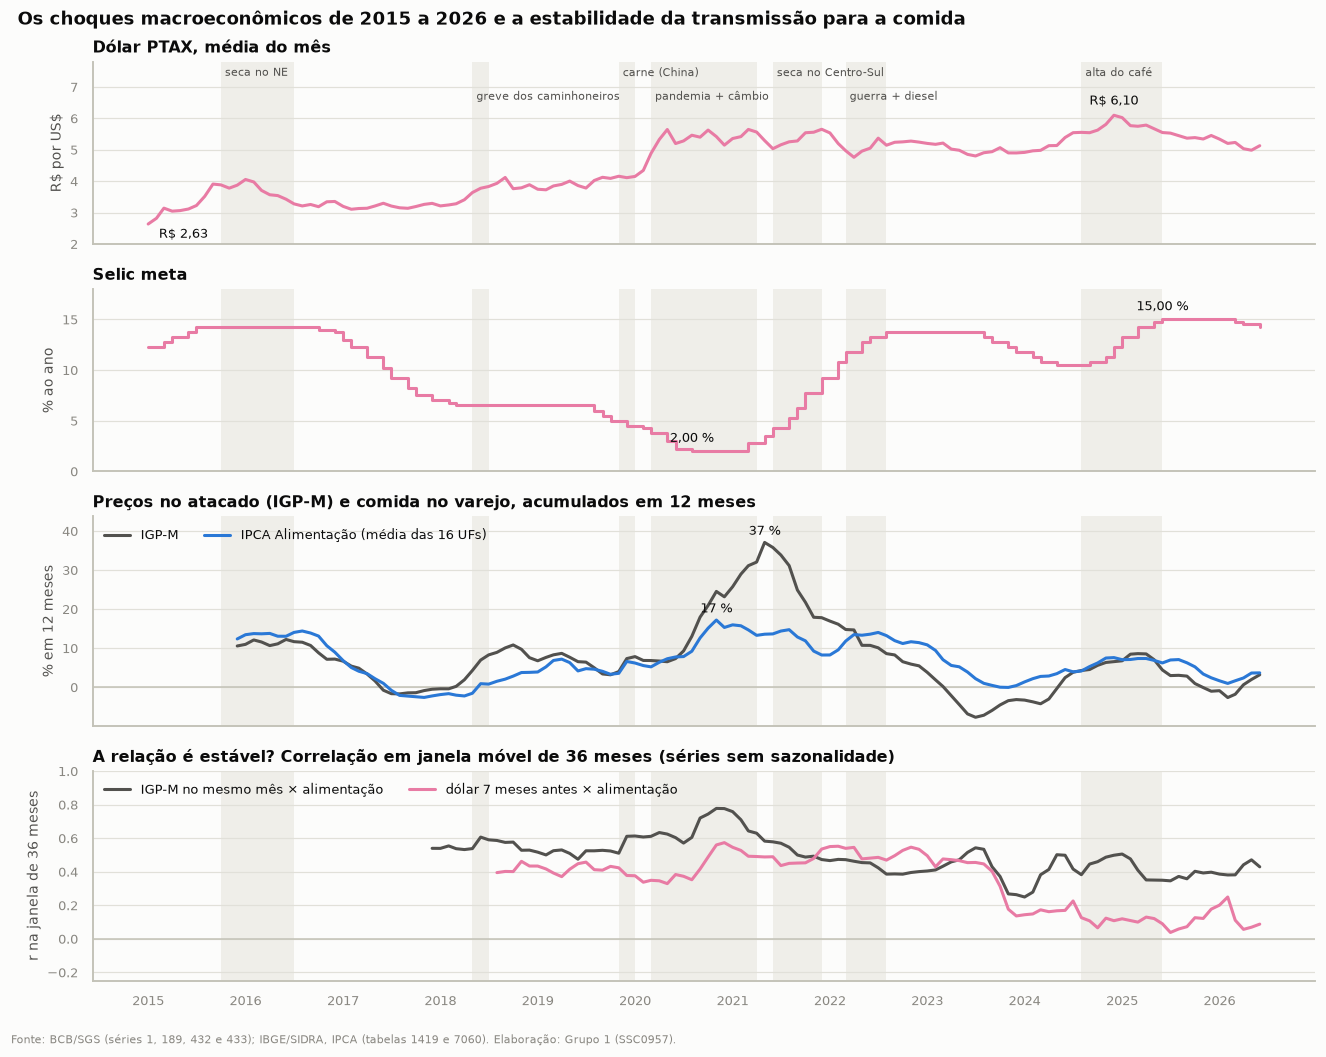

Correlação móvel do dólar (t−7): de +0.04 (2025-07) a +0.57 (2020-12); a do IGP-M: de +0.25 (2024-01) a +0.78 (2020-11).


In [14]:
def acum12(var_pct):
    """Acumulado composto em 12 meses a partir de variações mensais em %."""
    return ((1 + var_pct / 100).rolling(12).apply(np.prod, raw=True) - 1) * 100


def rolante(x, y, k, janela=36):
    par = pd.concat([x.shift(k), y], axis=1, keys=["x", "y"])
    return par["x"].rolling(janela, min_periods=janela).corr(par["y"])


alim_nac = serie_nacional(fato[ALVO])  # média das UFs, com sazonalidade (é o que o consumidor vê)
K_DOLAR = int(picos_nac.loc["macro_dolar_var_mm", "lag"])
fig, axes = plt.subplots(4, 1, figsize=(12, 9.4), sharex=True, gridspec_kw={"height_ratios": [1, 1, 1.15, 1.15]})
for i, ax in enumerate(axes):
    marcar_eventos(ax, rotulos=(i == 0))
    eixo_tempo(ax)

ax = axes[0]
s = macro["macro_dolar_ptax_medio"].set_axis(DATAS)
ax.plot(s.index, s, color=CORES["macro"])
reais = lambda v: f"R\\$ {v:.2f}".replace(".", ",")
ax.annotate(reais(s.max()), (s.idxmax(), s.max()), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.5)
ax.annotate(reais(s.iloc[0]), (s.index[0], s.iloc[0]), xytext=(7, -9), textcoords="offset points", ha="left", fontsize=8.5)
ax.set_ylim(2.0, s.max() * 1.28)
ax.set_ylabel("R\\$ por US\\$")
ax.set_title("Dólar PTAX, média do mês")

ax = axes[1]
s = macro["macro_selic"].set_axis(DATAS)
ax.step(s.index, s, where="post", color=CORES["macro"])
for quando, dy in [(s.idxmin(), 6), (s.idxmax(), 6)]:
    ax.annotate(f"{s[quando]:.2f} %".replace(".", ","), (quando, s[quando]), xytext=(0, dy), textcoords="offset points",
                ha="center", fontsize=8.5)
ax.set_ylim(0, s.max() * 1.2)
ax.set_ylabel("% ao ano")
ax.set_title("Selic meta")

ax = axes[2]
igpm12, alim12 = acum12(macro["macro_igpm"]).set_axis(DATAS), acum12(alim_nac).set_axis(DATAS)
ax.axhline(0, color=NEUTRO, linewidth=1)
ax.plot(igpm12.index, igpm12, color=TINTA_2, label="IGP-M")
ax.plot(alim12.index, alim12, color=CORES["ipca"], label="IPCA Alimentação (média das 16 UFs)")
for serie in (igpm12, alim12):
    ax.annotate(f"{serie.max():.0f} %", (serie.idxmax(), serie.max()), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=8.5)
ax.set_ylim(top=igpm12.max() * 1.18)
ax.set_ylabel("% em 12 meses")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
ax.set_title("Preços no atacado (IGP-M) e comida no varejo, acumulados em 12 meses")

ax = axes[3]
rol_igpm = rolante(NAC["macro_igpm"], NAC[ALVO], 0).set_axis(DATAS)
rol_dolar = rolante(NAC["macro_dolar_var_mm"], NAC[ALVO], K_DOLAR).set_axis(DATAS)
ax.axhline(0, color=NEUTRO, linewidth=1)
ax.plot(rol_igpm.index, rol_igpm, color=TINTA_2, label="IGP-M no mesmo mês × alimentação")
ax.plot(rol_dolar.index, rol_dolar, color=CORES["macro"], label=f"dólar {K_DOLAR} meses antes × alimentação")
ax.set_ylim(-0.25, 1.0)
ax.set_ylabel("r na janela de 36 meses")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
ax.set_title("A relação é estável? Correlação em janela móvel de 36 meses (séries sem sazonalidade)")

fig.suptitle("Os choques macroeconômicos de 2015 a 2026 e a estabilidade da transmissão para a comida",
             x=0.005, ha="left", fontweight="bold", fontsize=11.5)
plt.tight_layout()
finalizar(fig, "fig_14_03_choques_macro_dolar_selic", "macro", "ipca")
plt.show()
print(f"Correlação móvel do dólar (t−{K_DOLAR}): de {rol_dolar.min():+.2f} ({rol_dolar.idxmin():%Y-%m}) a "
      f"{rol_dolar.max():+.2f} ({rol_dolar.idxmax():%Y-%m}); a do IGP-M: de {rol_igpm.min():+.2f} "
      f"({rol_igpm.idxmin():%Y-%m}) a {rol_igpm.max():+.2f} ({rol_igpm.idxmax():%Y-%m}).")

**Leitura (`fig_14_03`):**

- **Dólar:** de R\$ 2,63 (2015-01) a R\$ 6,10 (2024-12), em dois degraus: 2015 e 2020. Depois de 2020 ele nunca
  mais volta ao patamar anterior.
- **Selic:** dois ciclos completos. De 14,25 % para 2,00 % (2020-08), de volta a 13,75 %, e até 15,00 % (2025-06).
  Ela sobe **depois** de cada pico de inflação, o que a figura 1 já havia mostrado nos lags negativos.
- **Atacado × varejo:** em 12 meses, o IGP-M chegou a **37 %** (2021-05) e a comida no varejo a **17 %** (2020-11).
  O atacado amplifica o choque; o varejo recebe menos da metade. Em 2023 o IGP-M chegou a −8 % e a comida ficou
  perto de zero, sem acompanhar a queda: mais uma vez, a baixa não repassa como a alta.
- **Estabilidade (último painel):** a correlação do IGP-M fica entre +0,25 e +0,78 e **nunca cruza o zero**. A do
  dólar com 7 meses de atraso tem média de +0,4 a +0,5 nas janelas que terminam entre 2018 e 2023 e **cai para
  cerca de +0,1 nas que terminam de 2024 em diante**. Há uma quebra, e o item 3.3 mostra o que mudou.

### 3.2 Anatomia de cada episódio

Para cada episódio, o que as séries macro faziam, quanto a comida subiu, quanto disso estava acima do típico para
aqueles meses do ano, que itens puxaram, e se havia medição de diesel.

In [15]:
def composto(var_pct):
    return ((1 + var_pct / 100).prod() - 1) * 100


itens_nac = pd.DataFrame({c: serie_nacional(fato[c]) for c in ITENS if c != ALVO})
alim_uf = largo(fato[ALVO])
dolar = macro["macro_dolar_ptax_medio"]
linhas = []
for ini, fim, nome, _ in EVENTOS:
    a, b = pd.Period(ini, "M"), pd.Period(fim, "M")
    antes = max(a - 7, MESES[0])  # o dólar age com meses de atraso: olhamos também os 7 meses anteriores
    jan = slice(a, b)
    por_uf = alim_uf.loc[jan].dropna(axis=1).apply(composto)  # só UFs que já estavam no IPCA
    por_item = itens_nac.loc[jan].apply(composto).sort_values(ascending=False)
    liquidos = fato[fato["ano_mes"].between(a, b)].groupby("ano_mes")["comb_observado_liquidos"].any()
    linhas.append({
        "episódio": nome, "janela": f"{ini} a {fim}", "meses": len(MESES[(MESES >= a) & (MESES <= b)]),
        "dólar nos 7 meses antes (%)": (dolar[a - 1] / dolar[antes] - 1) * 100 if a - 1 > antes else np.nan,
        "dólar na janela (%)": (dolar[b] / dolar[max(a - 1, MESES[0])] - 1) * 100,
        "Selic (p.p.)": macro["macro_selic"][b] - macro["macro_selic"][max(a - 1, MESES[0])],
        "IGP-M (%)": composto(macro.loc[jan, "macro_igpm"]),
        "IPCA geral (%)": composto(macro.loc[jan, "macro_ipca_mm"]),
        "alimentação (%)": composto(alim_nac.loc[jan]),
        "acima do típico (p.p.)": NAC.loc[jan, ALVO].sum(),
        "UF: mín. a máx. (%)": f"{por_uf.min():.1f} ({por_uf.idxmin()}) a {por_uf.max():.1f} ({por_uf.idxmax()})",
        "itens que mais subiram": ", ".join(f"{NOME_ITEM[c]} {v:+.0f}%" for c, v in por_item.head(2).items()),
        "meses com diesel medido": f"{int(liquidos.sum())}/{len(liquidos)}",
    })
episodios = pd.DataFrame(linhas).set_index("episódio")
display(episodios.round(1))

,janela,meses,dólar nos 7 meses antes (%),dólar na janela (%),Selic (p.p.),IGP-M (%),IPCA geral (%),alimentação (%),acima do típico (p.p.),UF: mín. a máx. (%),itens que mais subiram,meses com diesel medido
episódio,,,,,,,,,,,,
seca no NE,2015-10 a 2016-06,9,24.4,-12.3,0.0,10.1,7.4,12.4,5.4,10.2 (SP) a 14.9 (PA),"batata-inglesa +84%, açúcares +32%",2/9
greve dos caminhoneiros,2018-05 a 2018-06,2,6.8,10.7,0.0,3.3,1.7,2.2,1.5,0.6 (PA) a 3.5 (PR),"batata-inglesa +37%, leite longa vida +15%",0/2
carne (China),2019-11 a 2019-12,2,4.9,0.6,-0.5,2.4,1.7,4.3,2.3,2.7 (SE) a 6.6 (GO),"carnes +26%, tomate +7%",2/2
pandemia + câmbio,2020-03 a 2021-03,13,8.0,30.1,-1.5,32.7,6.2,15.9,7.4,13.8 (DF) a 21.2 (AC),"óleo de soja +81%, arroz +63%",12/13
seca no Centro-Sul,2021-06 a 2021-11,6,-2.3,5.0,4.2,2.1,5.9,4.7,2.9,0.2 (PA) a 7.2 (ES),"tomate +52%, café moído +35%",5/6
guerra + diesel,2022-03 a 2022-07,5,-1.0,3.3,2.5,4.5,3.2,6.5,3.8,4.5 (SE) a 10.7 (RS),"leite longa vida +65%, leites e derivados +33%",5/5
alta do café,2024-08 a 2025-05,10,12.8,2.3,4.2,5.5,4.7,7.6,1.0,4.2 (SE) a 9.9 (PA),"café moído +71%, tomate +33%",10/10


**Leitura:** os sete episódios não são do mesmo tipo.

| Episódio | O que os dados mostram | Tipo |
|---|---|---|
| **Seca no NE (2015-16)** | o dólar tinha subido 24 % nos 7 meses anteriores; a comida sobe 12,4 % (5,4 p.p. acima do típico) | **câmbio + clima**: o episódio "climático" veio logo depois da maior desvalorização do período |
| **Greve (2018)** | +2,2 % em 2 meses; batata +37 %, leite longa vida +15 %; **0 de 2 meses com diesel medido** | logístico, e a tabela está **cega** para ele |
| **Carne (2019)** | +4,3 % em 2 meses, carnes +26 %; dólar quase parado na janela (+0,6 %); o IGP-M sobe 2,4 %, no mesmo mês da carne | choque de **um item** que aparece junto no atacado: não é câmbio nem clima |
| **Pandemia + câmbio (2020-21)** | dólar +30 %, IGP-M +33 %, comida +15,9 % (7,4 p.p. acima do típico); óleo de soja +81 %, arroz +63 % | **o choque macro por excelência** |
| **Seca no Centro-Sul (2021)** | dólar quase parado (−2 % antes, +5 % na janela); tomate +52 %, café +35 %; Selic +4,2 p.p. | clima, com os itens que a matriz não explica |
| **Guerra + diesel (2022)** | +6,5 % em 5 meses; leite longa vida +65 %; RS +10,7 % contra SE +4,5 % | custo, com forte diferença entre UFs |
| **Café (2024-25)** | café +71 %, mas a comida fica só **1,0 p.p.** acima do típico em 10 meses | choque de **um item**, que o grupo dilui |

Três observações:

1. **A greve dos caminhoneiros não pode ser estudada com esta tabela.** A ANP não tem pesquisa de combustíveis
   líquidos de 2018-04 a 2018-06. É a limitação de representatividade temporal mais séria para a hipótese de
   logística.
2. **O maior episódio é macro**, e é ele que mais pesa na correlação do dólar: sem 2020, o r em `t−7` cai de +0,35
   para +0,24 (item 3.3).
3. **A diferença entre UFs aparece nos episódios, não na média.** Na pandemia, a comida subiu de 13,8 % (DF) a
   21,2 % (AC). É o achado 3 do notebook 09 (as UFs divergem nos choques), visto por episódio.

### 3.3 O lag é o mesmo em todos os períodos? Quem antecede quem?

Duas tabelas. A primeira refaz a CCF em três períodos e tirando um ano por vez. A segunda é o teste de Granger nos
dois sentidos; a estacionariedade que ele exige foi conferida na Seção 1.1.

In [16]:
# ---- O lag é o mesmo em todo período? E quem antecede quem? -------------------------------------
PERIODOS = {"2015–2019": ("2015-01", "2019-12"), "2020–2022": ("2020-01", "2022-12"), "2023–2026": ("2023-01", "2026-06")}
PARES = ["macro_igpm", "macro_dolar_var_mm", "comb_var_mm_diesel", "clima_dias_calor_extremo"]
linhas = []
for col in PARES:
    k0 = int(picos_nac.loc[col, "lag"])
    par = pd.concat([NAC[col].shift(k0), NAC[ALVO]], axis=1, keys=["x", "y"]).dropna()
    sem_ano = pd.Series({a: par[par.index.year != a]["x"].corr(par[par.index.year != a]["y"]) for a in sorted(set(par.index.year))})
    linha = {"driver": DRIVERS.loc[col, "rotulo"], "amostra inteira": f"{picos_nac.loc[col, 'r']:+.2f} em {em_t(k0)}"}
    for nome, (ini, fim) in PERIODOS.items():
        y = NAC[ALVO].loc[ini:fim]
        t = ccf(NAC[col], y, minimo=20)   # x pode olhar para trás do período; o alvo fica dentro dele
        if t["r"].notna().any():
            k = t["r"].abs().idxmax()
            no_k0 = f"{t.loc[k0, 'r']:+.2f}" if pd.notna(t.loc[k0, "r"]) else "sem dado"
            linha[nome] = f"{t.loc[k, 'r']:+.2f} em {em_t(k)} (n={int(t.loc[k, 'n'])}); em {em_t(k0)}: {no_k0}"
        else:
            linha[nome] = "sem dado suficiente"
    linha["tirando 1 ano por vez"] = f"{sem_ano.min():+.2f} (sem {sem_ano.idxmin()}) a {sem_ano.max():+.2f}"
    linhas.append(linha)
display(pd.DataFrame(linhas).set_index("driver"))

# Precedência temporal (Granger). Estacionariedade conferida na ficha técnica da Seção 1.
ORDENS = [1, 2, 3, 6, 8, 12]
linhas = []
for col in ["macro_dolar_var_mm", "macro_igpm", "macro_selic_delta"]:
    d = pd.concat([NAC[ALVO], NAC[col]], axis=1, keys=["y", "x"]).dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ida = grangercausalitytests(d[["y", "x"]], maxlag=ORDENS)
        volta = grangercausalitytests(d[["x", "y"]], maxlag=ORDENS)
    for nome, res in [("driver → preço", ida), ("preço → driver", volta)]:
        linhas.append({"driver": DRIVERS.loc[col, "rotulo"], "direção": nome,
                       **{f"{k} lag{'s' if k > 1 else ''}": res[k][0]["ssr_ftest"][1] for k in ORDENS}})
granger = pd.DataFrame(linhas).set_index(["driver", "direção"])
print("Teste de Granger: p-valor do teste F, por número de defasagens incluídas (n = 137 meses)")
display(granger.round(3))

,amostra inteira,2015–2019,2020–2022,2023–2026,tirando 1 ano por vez
driver,,,,,
IGP-M no mês (%),+0.52 em t,+0.58 em t (n=60); em t: +0.58,+0.44 em t−2 (n=36); em t: +0.40,+0.49 em t−4 (n=42); em t: +0.46,+0.40 (sem 2020) a +0.63
Dólar: variação no mês (%),+0.35 em t−7,+0.35 em t−7 (n=52); em t−7: +0.35,+0.53 em t−7 (n=36); em t−7: +0.53,+0.40 em t−4 (n=42); em t−7: +0.08,+0.24 (sem 2020) a +0.39
Diesel: variação no mês (%),+0.22 em t−4,+0.22 em t−2 (n=21); em t−4: sem dado,-0.60 em t−7 (n=28); em t−4: +0.06,+0.42 em t−5 (n=42); em t−4: +0.40,+0.13 (sem 2022) a +0.34
Dias de calor extremo,+0.26 em t−1,+0.45 em t−1 (n=59); em t−1: +0.45,+0.53 em t−1 (n=36); em t−1: +0.53,+0.48 em t−5 (n=42); em t−1: +0.23,+0.22 (sem 2017) a +0.31


Teste de Granger: p-valor do teste F, por número de defasagens incluídas (n = 137 meses)


1 lag  2 lags  3 lags  6 lags  8 lags  12 lags
driver                        direção                                                       
Dólar: variação no mês (%)    driver → preço  0.556   0.787   0.885   0.052   0.006    0.240
                              preço → driver  0.466   0.740   0.652   0.118   0.054    0.011
IGP-M no mês (%)              driver → preço  0.002   0.007   0.018   0.100   0.252    0.720
                              preço → driver  0.300   0.445   0.260   0.259   0.344    0.160
Selic: variação no mês (p.p.) driver → preço  0.079   0.194   0.034   0.033   0.126    0.282
                              preço → driver  0.010   0.157   0.236   0.362   0.232    0.432

**Leitura:**

- **IGP-M: estável.** No mesmo mês, r de +0,40 a +0,58 nos três períodos, e nunca abaixo de +0,40 tirando qualquer
  ano.
- **Dólar: o atraso encurtou.** O pico é em `t−7` em 2015-19 (+0,35) e em 2020-22 (+0,53). Em 2023-26 ele se desloca
  para **`t−4`** (+0,40), e em `t−7` sobra +0,08. Sem 2020, o r em `t−7` é +0,24: menor, mas ainda positivo. A
  conclusão segura é **"o dólar antecede a comida em 4 a 8 meses"**, não "em 7".
- **Diesel: instável.** O sinal troca entre períodos (−0,60 em 2020-22, com 28 meses; +0,42 em 2023-26). Com tantos
  buracos antes de 2021, não há como estimar um lag confiável.
- **Calor extremo:** `t−1` em dois dos três períodos (+0,45 e +0,53). É o sinal climático mais consistente no
  tempo, embora não passe no FDR na amostra inteira.

**Granger** (precedência temporal, **não** causalidade):

- **IGP-M → preço:** p de 0,002 a 0,018 com 1 a 3 defasagens; o sentido inverso não é significativo. O atacado
  antecede o varejo.
- **Dólar → preço:** só aparece com 8 defasagens (p = 0,006), o que bate com o atraso da CCF.
- **Selic:** a precedência mais forte é **preço → Selic** (1 defasagem, p = 0,010). Confirma a leitura de
  causalidade invertida. A variação da Selic teve estacionariedade inconclusiva; o teste vale como indício.

> **Para a modelagem (T-041):** em vez de um único lag do dólar, usar uma janela (por exemplo, a variação média de
> `t−4` a `t−8`). Um lag fixo em 7 teria perdido o sinal em 2023-26.

## 4. Representatividade espacial por propósito & síntese multicritério

> **Objetivo:** responder à pergunta central **por região**, dizendo também para que propósito os dados de cada
> região servem e para qual não servem.

Os cadernos 10 a 13 ainda não tinham resultados gravados na data desta execução. Para a síntese não depender deles,
ela recalcula aqui, com a mesma régua, um conjunto de indicadores de cada família (macro, combustíveis, seca, clima
e safra). A tabela `outputs/tabelas/eda_14_sintese_multicriterio.csv` é o ponto de encontro quando as outras
frentes fecharem.

### 4.1 As cinco regiões são cinco amostras diferentes?

In [17]:
# ---- 4.1 Quão diferentes são as regiões? E quanto dado cada uma tem? ----------------------------
def serie_regiao(s, regiao):
    return serie_nacional(s, grupo=fato["regiao"] == regiao)


Y_REG = pd.DataFrame({r: serie_regiao(A[ALVO], r) for r in REGIOES})
balanceada = obter_janela_analise(fato, "balanceada")
linhas = []
for r in REGIOES:
    y = Y_REG[r]
    ajuste = sm.OLS(y, sm.add_constant(NAC[ALVO])).fit()
    sub = fato[fato["regiao"] == r]
    linhas.append({
        "região": r, "UFs no IPCA": ", ".join(sorted(sub["sigla_uf"].unique())),
        "r com o Brasil": y.corr(NAC[ALVO]), "beta ao ciclo nacional": ajuste.params.iloc[1],
        "% explicado pelo Brasil": ajuste.rsquared * 100, "desvio-padrão do que sobra (p.p.)": ajuste.resid.std(),
        "meses na janela balanceada (por UF)": " / ".join(
            str(int((balanceada["sigla_uf"] == uf).sum())) for uf in sorted(sub["sigla_uf"].unique())),
        "seca medida desde": sub.loc[sub["seca_monitorado"], "ano_mes"].groupby(sub["sigla_uf"]).min().max(),
    })
display(pd.DataFrame(linhas).set_index("região").round(2))
print("Correlação entre as séries regionais (sem sazonalidade):")
display(Y_REG.corr().round(2))

,UFs no IPCA,r com o Brasil,beta ao ciclo nacional,% explicado pelo Brasil,desvio-padrão do que sobra (p.p.),meses na janela balanceada (por UF),seca medida desde
região,,,,,,,
Norte,"AC, PA",0.85,0.94,71.81,0.41,44 / 39,2023-04
Nordeste,"BA, CE, MA, PE, SE",0.94,0.98,87.76,0.26,105 / 105 / 83 / 105 / 82,2018-05
Centro-Oeste,"DF, GO, MS",0.95,1.08,89.44,0.26,68 / 69 / 68,2020-07
Sudeste,"ES, MG, RJ, SP",0.96,1.03,91.82,0.22,80 / 82 / 70 / 65,2020-11
Sul,"PR, RS",0.90,0.96,81.84,0.32,67 / 67,2020-08


Correlação entre as séries regionais (sem sazonalidade):


,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
Norte,1.00,0.80,0.77,0.75,0.70
Nordeste,0.80,1.00,0.83,0.84,0.81
Centro-Oeste,0.77,0.83,1.00,0.91,0.83
Sudeste,0.75,0.84,0.91,1.00,0.86
Sul,0.70,0.81,0.83,0.86,1.00


**Leitura:**

- **As regiões se parecem muito.** A correlação com o Brasil vai de 0,85 (Norte) a 0,96 (Sudeste), e o beta ao
  ciclo nacional fica entre 0,94 e 1,08. O Brasil sozinho explica de 72 % (Norte) a 92 % (Sudeste) da série de cada
  região.
- **"Região" aqui são poucas capitais.** O Norte são **AC e PA** (e o AC só entra em 2018-05); o Sul são PR e RS; o
  Centro-Oeste são DF, GO e MS, **sem o Mato Grosso**, o maior produtor de grãos do país.
- **A cobertura não é igual.** Na janela balanceada (combustível e seca medidos ao mesmo tempo), o Nordeste tem até
  105 meses por UF e o Norte tem 44 e 39. A seca só é medida no Norte inteiro a partir de 2023-04.
- **O Norte é a região mais diferente e a menos medida.** É onde sobra mais variação própria (desvio-padrão de 0,41
  p.p. depois de tirar o Brasil) e onde há menos dado para explicá-la.

### 4.2 Os critérios

Cada par região × driver é avaliado por **cinco critérios**, não por um número só:

| Critério | Como é medido |
|---|---|
| **Força** | r no lag ótimo (0 a 12 meses), séries sem sazonalidade |
| **Antecedência** | o lag ótimo, em meses |
| **Significância** | p-valor com n efetivo; FDR de 5 % sobre todos os testes da camada |
| **Estabilidade** | o cálculo é refeito tirando um ano por vez: o sinal se mantém? a força cai para menos da metade? |
| **Cobertura** | % dos 138 meses em que o par tem dado |

Os critérios viram três graus de evidência:

- **robusta:** passa no FDR **e** é estável;
- **sugestiva:** não passa no FDR, mas p × 13 < 0,05 (corrigido pela busca do lag) e o sinal não muda;
- **fraca:** todo o resto, **por maior que seja o r**.

Há duas matrizes. Em **total**, a inflação da região contra o driver da região. Em **desvio**, o que a região tem
de diferente do Brasil contra o que o driver da região tem de diferente do Brasil.

In [18]:
# ---- 4.2 Síntese multicritério: região × driver ------------------------------------------------
SINTESE = ["macro_igpm", "macro_dolar_var_mm", "comb_var_mm_diesel", "comb_var_mm_glp_13kg", "seca_severidade_media",
           "clima_dias_calor_extremo", "clima_max_dias_secos_seguidos", "clima_chuva_mm_mes",
           "safra_revisao_pct_milho", "safra_revisao_pct_feijao"]
ESCOPOS = ["Brasil", *REGIOES]


def do_escopo(col, escopo):
    return NAC[col] if escopo == "Brasil" else serie_regiao(A[col], escopo)


linhas = []
for escopo in ESCOPOS:
    y = do_escopo(ALVO, escopo)
    for col in SINTESE:
        x = do_escopo(col, escopo)
        linhas.append(ccf(x, y).assign(escopo=escopo, driver=col, camada="total").reset_index())
        if escopo != "Brasil" and col in DRIVERS_UF:
            # o que a região tem de diferente do país: desvio do preço × desvio do driver
            linhas.append(ccf(x - NAC[col], y - NAC[ALVO]).assign(escopo=escopo, driver=col, camada="desvio").reset_index())
MC = pd.concat(linhas, ignore_index=True)
MC["p_fdr"] = MC.groupby("camada")["p"].transform(fdr)
mc = pico(MC, chaves=("camada", "escopo", "driver")).reset_index()


def estabilidade(l):
    """Tira um ano por vez no lag ótimo: o sinal se mantém? A força cai para menos da metade?"""
    x, y = do_escopo(l["driver"], l["escopo"]), do_escopo(ALVO, l["escopo"])
    if l["camada"] == "desvio":
        x, y = x - NAC[l["driver"]], y - NAC[ALVO]
    par = pd.concat([x.shift(l["lag"]), y], axis=1, keys=["x", "y"]).dropna()
    rs = np.array([par[par.index.year != a]["x"].corr(par[par.index.year != a]["y"]) for a in sorted(set(par.index.year))])
    return pd.Series({"r_min_sem_1_ano": rs[np.abs(rs).argmin()], "sinal_estavel": bool((np.sign(rs) == np.sign(l["r"])).all())})


mc = pd.concat([mc, mc.apply(estabilidade, axis=1)], axis=1)
mc["cobertura_pct"] = mc["n"] / len(MESES) * 100
robusto = (mc["p_fdr"] < 0.05) & mc["sinal_estavel"] & (mc["r_min_sem_1_ano"].abs() >= 0.5 * mc["r"].abs())
sugestivo = (mc["p"] * len(LAGS) < 0.05) & mc["sinal_estavel"]   # Bonferroni pela busca em 13 lags
mc["evidencia"] = np.select([robusto, sugestivo], ["robusta", "sugestiva"], "fraca")
mc["familia"] = mc["driver"].map(DRIVERS["familia"])
mc.assign(driver_rotulo=mc["driver"].map(DRIVERS["rotulo"])).to_csv(
    TABELAS / "eda_14_sintese_multicriterio.csv", index=False, float_format="%.4f")

print("Critérios por célula: força (r no lag ótimo), antecedência (lag), significância (p com n efetivo e FDR),")
print("estabilidade (tirando 1 ano por vez) e cobertura (% dos 138 meses com dado).")
print("\nQuantas células em cada grau de evidência:")
display(mc.groupby(["camada", "evidencia"]).size().unstack(fill_value=0))
print("Células robustas ou sugestivas, da mais forte para a mais fraca:")
display(mc[mc["evidencia"] != "fraca"].assign(driver=lambda d: d["driver"].map(DRIVERS["rotulo"]), abs_r=lambda d: d["r"].abs())
        .sort_values(["camada", "abs_r"], ascending=[False, False])
        [["camada", "escopo", "driver", "lag", "r", "p", "p_fdr", "r_min_sem_1_ano", "cobertura_pct", "evidencia"]].round(3))

Critérios por célula: força (r no lag ótimo), antecedência (lag), significância (p com n efetivo e FDR),
estabilidade (tirando 1 ano por vez) e cobertura (% dos 138 meses com dado).

Quantas células em cada grau de evidência:


evidencia,fraca,robusta,sugestiva
camada,,,
desvio,33,1,6
total,47,12,1


Células robustas ou sugestivas, da mais forte para a mais fraca:


,camada,escopo,driver,lag,r,p,p_fdr,r_min_sem_1_ano,cobertura_pct,evidencia
76,total,Norte,IGP-M no mês (%),1,0.556,0.000,0.004,0.417,99.275,robusta
46,total,Brasil,IGP-M no mês (%),0,0.523,0.000,0.004,0.404,100.000,robusta
56,total,Centro-Oeste,IGP-M no mês (%),0,0.507,0.000,0.004,0.401,100.000,robusta
96,total,Sul,IGP-M no mês (%),0,0.492,0.000,0.004,0.404,100.000,robusta
86,total,Sudeste,IGP-M no mês (%),0,0.466,0.000,0.006,0.348,100.000,robusta
66,total,Nordeste,IGP-M no mês (%),0,0.457,0.000,0.016,0.343,100.000,robusta
85,total,Sudeste,Dólar: variação no mês (%),7,0.361,0.000,0.012,0.239,94.203,robusta
75,total,Norte,Dólar: variação no mês (%),8,0.360,0.000,0.016,0.281,93.478,robusta
45,total,Brasil,Dólar: variação no mês (%),7,0.354,0.000,0.016,0.236,94.203,robusta
65,total,Nordeste,Dólar: variação no mês (%),7,0.329,0.001,0.025,0.227,94.203,robusta


**Leitura:** de 60 células na matriz total, **12 são robustas**: IGP-M nas seis linhas, dólar em cinco e uma de
clima. Na matriz de desvio, de 40 células, **1 é robusta** e 6 são sugestivas. A figura 4 mostra onde estão.

### 4.3 Quanto cada família explica

Para dar um tamanho a cada família, repartimos o R² de uma regressão por região entre quatro blocos, pelo método de
Shapley (a contribuição média do bloco em todas as ordens de entrada). Os lags são **fixos e iguais para todas as
regiões**, escolhidos na camada nacional: IGP-M em `t` e `t−1`, dólar na média de `t−4` a `t−8`, calor extremo em
`t−1`, veranico em `t−3`, chuva em `t−1`, revisões de milho e feijão em `t−1`.

Combustíveis e seca **ficam de fora** desta conta: só existem juntos na janela balanceada, que no Norte tem 39
meses. A evidência sobre eles está nas matrizes.

In [19]:
# ---- 4.3 Orçamento da variância por família (Shapley), na janela longa -------------------------
def r2(y, X):
    if X.shape[1] == 0:
        return 0.0
    Xc = np.column_stack([np.ones(len(y)), X])
    res = y - Xc @ np.linalg.lstsq(Xc, y, rcond=None)[0]
    return 1 - res.var() / y.var()


def shapley_r2(y, blocos):
    """Reparte o R² entre famílias pela média do ganho em todas as ordens de entrada (LMG/Shapley)."""
    nomes = list(blocos)
    valor = {frozenset(S): r2(y, np.column_stack([blocos[s] for s in S]) if S else np.empty((len(y), 0)))
             for q in range(len(nomes) + 1) for S in itertools.combinations(nomes, q)}
    k = len(nomes)
    parte = {}
    for j in nomes:
        outros = [n for n in nomes if n != j]
        parte[j] = sum(math.factorial(q) * math.factorial(k - q - 1) / math.factorial(k)
                       * (valor[frozenset(S) | {j}] - valor[frozenset(S)])
                       for q in range(k) for S in itertools.combinations(outros, q))
    return parte, valor[frozenset(nomes)]


def r2_fora_da_amostra(y, X, anos):
    """Deixa um ano de fora por vez, ajusta no resto e prevê o ano que saiu."""
    Xc = np.column_stack([np.ones(len(y)), X])
    erro, base = 0.0, 0.0
    for a in np.unique(anos):
        tr, te = anos != a, anos == a
        beta = np.linalg.lstsq(Xc[tr], y[tr], rcond=None)[0]
        erro += ((y[te] - Xc[te] @ beta) ** 2).sum()
        base += ((y[te] - y[tr].mean()) ** 2).sum()
    return 1 - erro / base


# Lags fixos, escolhidos na camada nacional (Seções 1 e 2), iguais para todas as regiões.
dolar_acum = lambda: NAC["macro_dolar_var_mm"].shift(4).rolling(5).mean()   # média de t−4 a t−8
BLOCOS = ["sazonalidade", "macro", "clima", "safra"]
COR_BLOCO = {"sazonalidade": TINTA_3, "macro": CORES["macro"], "clima": CORES["clima"], "safra": CORES["safra"],
             "não explicado": "#e1e0d9"}
linhas = []
for escopo in ESCOPOS:
    y_bruto = serie_nacional(fato[ALVO], grupo=None if escopo == "Brasil" else fato["regiao"] == escopo)
    X = {
        "sazonalidade": pd.get_dummies(pd.Series(MESES.month, index=MESES), drop_first=True).astype(float),
        "macro": pd.concat([NAC["macro_igpm"], NAC["macro_igpm"].shift(1), dolar_acum()], axis=1),
        "clima": pd.concat([do_escopo("clima_dias_calor_extremo", escopo).shift(1),
                            do_escopo("clima_max_dias_secos_seguidos", escopo).shift(3),
                            do_escopo("clima_chuva_mm_mes", escopo).shift(1)], axis=1),
        "safra": pd.concat([do_escopo("safra_revisao_pct_milho", escopo).shift(1),
                            do_escopo("safra_revisao_pct_feijao", escopo).shift(1)], axis=1),
    }
    tudo = pd.concat([y_bruto.rename("y"), *[X[b].set_axis([f"{b}{i}" for i in range(X[b].shape[1])], axis=1) for b in BLOCOS]],
                     axis=1).dropna()
    blocos = {b: tudo[[c for c in tudo.columns if c.startswith(b)]].to_numpy() for b in BLOCOS}
    parte, r2_total = shapley_r2(tudo["y"].to_numpy(), blocos)
    fora = r2_fora_da_amostra(tudo["y"].to_numpy(), np.column_stack(list(blocos.values())), tudo.index.year.to_numpy())
    linhas.append({"escopo": escopo, **{b: v * 100 for b, v in parte.items()}, "não explicado": (1 - r2_total) * 100,
                   "meses": len(tudo), "parâmetros": sum(v.shape[1] for v in blocos.values()),
                   "R² dentro da amostra (%)": r2_total * 100, "R² deixando 1 ano fora (%)": fora * 100})
orcamento = pd.DataFrame(linhas).set_index("escopo")
display(orcamento.round(1))

,sazonalidade,macro,clima,safra,não explicado,meses,parâmetros,R² dentro da amostra (%),R² deixando 1 ano fora (%)
escopo,,,,,,,,,
Brasil,23.9,28.4,4.7,1.2,41.8,118,19,58.2,40.9
Norte,25.3,35.7,2.4,0.7,35.9,118,19,64.1,50.6
Nordeste,27.9,22.3,2.7,0.3,46.7,118,19,53.3,31.0
Centro-Oeste,20.8,26.1,7.6,3.4,42.1,118,19,57.9,41.2
Sudeste,19.5,25.5,3.2,0.3,51.4,118,19,48.6,25.4
Sul,18.1,26.7,0.8,4.8,49.6,118,19,50.4,29.8


**Leitura:** no Brasil, a sazonalidade responde por 24 % da variância, a dupla IGP-M e dólar por 28 %, o clima local
por 5 % e a safra local por 1 %. **Ficam 42 % sem explicação.**

- O bloco macro vai de 22 % (Nordeste) a 36 % (Norte). Clima e safra locais, somados, nunca passam de 11 %
  (Centro-Oeste).
- **Cautela com o R².** Dentro da amostra ele é 58 % no Brasil; deixando um ano de fora por vez, cai para **41 %**
  (de 25 % no Sudeste a 51 % no Norte). São 19 parâmetros para 118 meses. A repartição é uma descrição da amostra,
  não uma previsão.

figura salva: outputs/figuras/eda/fig_14_04_sintese_multicriterio_drivers_regiao.png


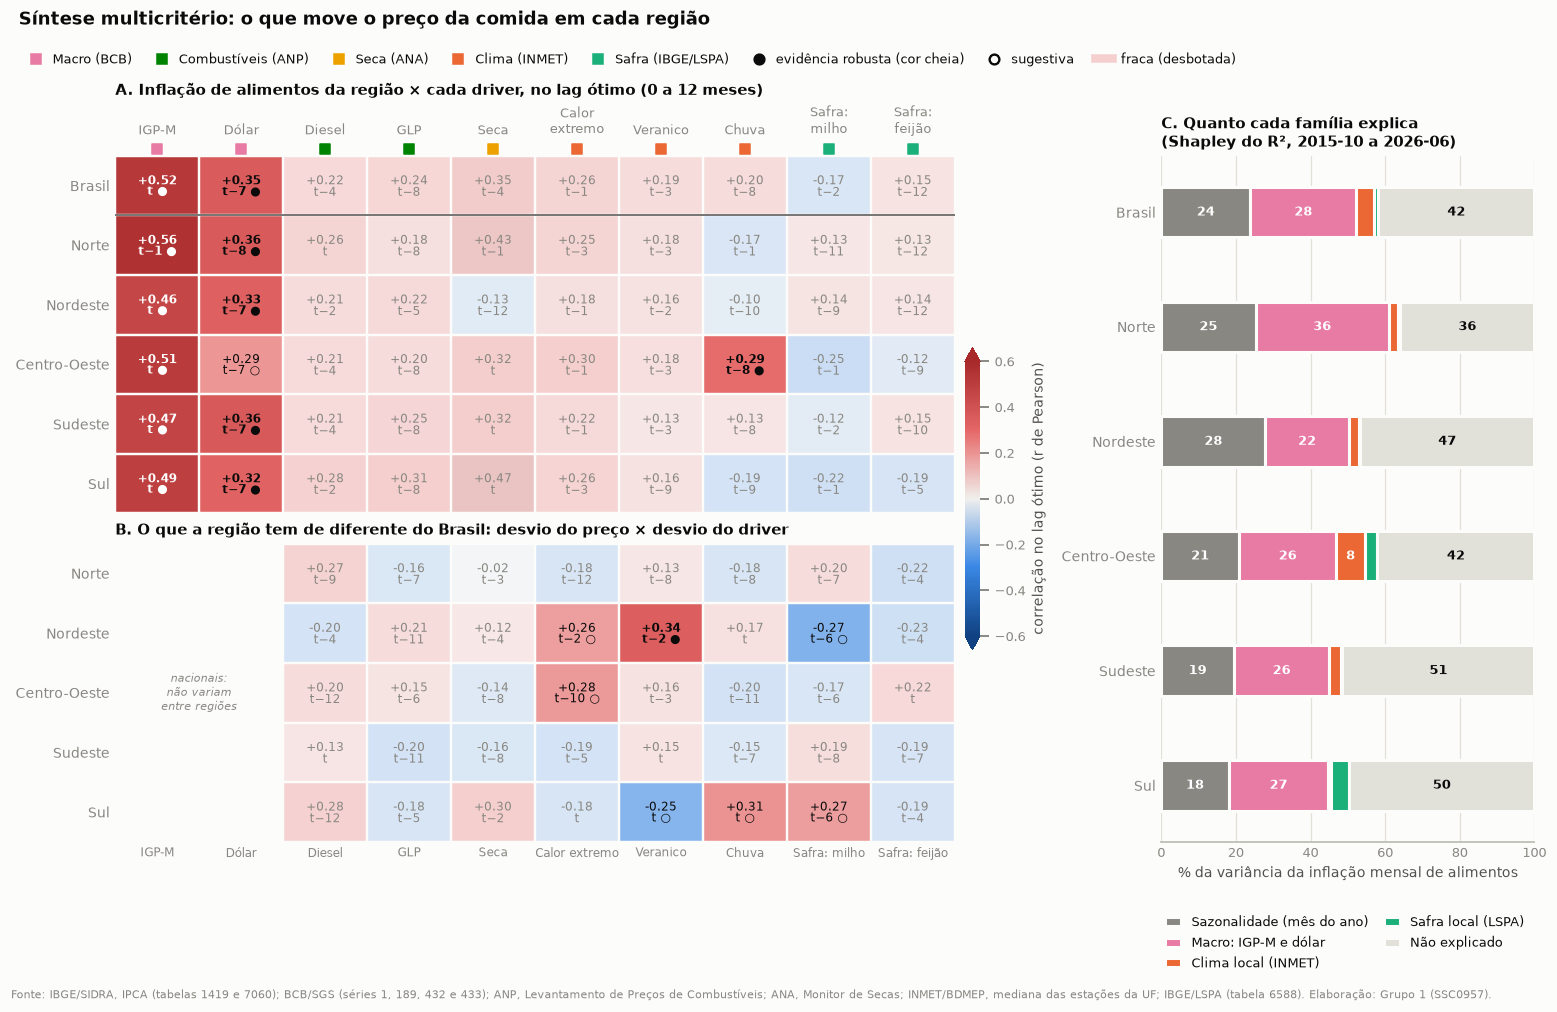

,1º (robusto),2º (robusto),outros robustos,assinatura regional (desvio vs. Brasil)
escopo,,,,
Brasil,"IGP-M (r=+0.52, t)","Dólar (r=+0.35, t−7)",—,—
Norte,"IGP-M (r=+0.56, t−1)","Dólar (r=+0.36, t−8)",—,—
Nordeste,"IGP-M (r=+0.46, t)","Dólar (r=+0.33, t−7)",—,"Veranico (r=+0.34, t−2) [robusta]; Safra: milho (r=-0.27, t−6) [sugestiva]"
Centro-Oeste,"IGP-M (r=+0.51, t)","Chuva (r=+0.29, t−8)",—,"Calor extremo (r=+0.28, t−10) [sugestiva]"
Sudeste,"IGP-M (r=+0.47, t)","Dólar (r=+0.36, t−7)",—,—
Sul,"IGP-M (r=+0.49, t)","Dólar (r=+0.32, t−7)",—,"Chuva (r=+0.31, t) [sugestiva]; Safra: milho (r=+0.27, t−6) [sugestiva]"


In [20]:
# ---- fig_14_04: a síntese em uma página ---------------------------------------------------------
curto_s = {"macro_igpm": "IGP-M", "macro_dolar_var_mm": "Dólar", "comb_var_mm_diesel": "Diesel",
           "comb_var_mm_glp_13kg": "GLP", "seca_severidade_media": "Seca", "clima_dias_calor_extremo": "Calor\nextremo",
           "clima_max_dias_secos_seguidos": "Veranico", "clima_chuva_mm_mes": "Chuva",
           "safra_revisao_pct_milho": "Safra:\nmilho", "safra_revisao_pct_feijao": "Safra:\nfeijão"}


def matriz_sintese(ax, camada, escopos, titulo):
    t = mc[mc["camada"] == camada].set_index(["escopo", "driver"])
    M = np.full((len(escopos), len(SINTESE)), np.nan)
    F = np.zeros_like(M)   # opacidade: o grau de evidência da célula
    for i, e in enumerate(escopos):
        for j, c in enumerate(SINTESE):
            if (e, c) not in t.index:
                continue
            l = t.loc[(e, c)]
            M[i, j] = l["r"]
            forte = l["evidencia"] == "robusta"
            F[i, j] = {"robusta": 1.0, "sugestiva": 0.7, "fraca": 0.3}[l["evidencia"]]
            marca = {"robusta": "●", "sugestiva": "○", "fraca": ""}[l["evidencia"]]
            ax.text(j, i, f"{l['r']:+.2f}\n{em_t(l['lag'])} {marca}".rstrip(), ha="center", va="center", fontsize=7.6,
                    linespacing=1.0, fontweight="bold" if forte else "normal",
                    color=("#ffffff" if forte and abs(l["r"]) > 0.4 else TINTA) if l["evidencia"] != "fraca" else TINTA_3)
    rgba = DIVERGENTE(plt.Normalize(-0.6, 0.6)(np.nan_to_num(M)))
    rgba[..., 3] = F
    ax.imshow(rgba, aspect="auto")
    if camada == "desvio":
        ax.text(0.5, (len(escopos) - 1) / 2, "nacionais:\nnão variam\nentre regiões", ha="center", va="center",
                fontsize=7.5, color=TINTA_3, style="italic")
    ax.set_yticks(range(len(escopos)), escopos, fontsize=9)
    ax.set_xticks(np.arange(-0.5, len(SINTESE)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(escopos)), minor=True)
    ax.grid(False)
    ax.grid(which="minor", color=FUNDO, linewidth=1.6)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(titulo, fontsize=10)


fig = plt.figure(figsize=(14, 8.2), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=[2.25, 1], height_ratios=[6, 5])
ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[:, 1])

matriz_sintese(ax1, "total", ESCOPOS, "A. Inflação de alimentos da região × cada driver, no lag ótimo (0 a 12 meses)")
ax1.set_xticks(range(len(SINTESE)), [curto_s[c] for c in SINTESE], fontsize=8.5)
ax1.xaxis.tick_top()
ax1.tick_params(axis="x", pad=12)
for j, c in enumerate(SINTESE):
    ax1.scatter(j, 1.02, marker="s", s=38, color=CORES[DRIVERS.loc[c, "familia"]], transform=ax1.get_xaxis_transform(),
                clip_on=False, zorder=6)
ax1.axhline(0.5, color=TINTA_2, linewidth=1)
matriz_sintese(ax2, "desvio", REGIOES, "B. O que a região tem de diferente do Brasil: desvio do preço × desvio do driver")
ax2.set_xticks(range(len(SINTESE)), [curto_s[c].replace("\n", " ") for c in SINTESE], fontsize=8)
barra_de_cor(fig, [ax1, ax2], 0.6, "correlação no lag ótimo (r de Pearson)", fraction=0.018, pad=0.012)

# C. orçamento da variância
ordem = ESCOPOS[::-1]
esq = np.zeros(len(ordem))
for b in [*BLOCOS, "não explicado"]:
    v = orcamento.loc[ordem, b].to_numpy()
    ax3.barh(range(len(ordem)), v, left=esq, height=0.44, color=COR_BLOCO[b], edgecolor=FUNDO, linewidth=2,
             label={"sazonalidade": "Sazonalidade (mês do ano)", "macro": "Macro: IGP-M e dólar",
                    "clima": "Clima local (INMET)", "safra": "Safra local (LSPA)", "não explicado": "Não explicado"}[b])
    for i, (x0, w) in enumerate(zip(esq, v)):
        if w >= 7:
            ax3.text(x0 + w / 2, i, f"{w:.0f}", ha="center", va="center", fontsize=8.5,
                     color=TINTA if b in ("não explicado", "safra") else "#ffffff", fontweight="bold")
    esq += v
ax3.set_yticks(range(len(ordem)), ordem, fontsize=9)
ax3.set_xlim(0, 100)
ax3.set_xlabel("% da variância da inflação mensal de alimentos")
ax3.grid(axis="y", visible=False)
ax3.tick_params(length=0)
ax3.spines["left"].set_visible(False)
ax3.legend(loc="upper left", bbox_to_anchor=(-0.02, -0.09), ncol=2, fontsize=8.5, handlelength=1.2, columnspacing=1.2)
ax3.set_title("C. Quanto cada família explica\n(Shapley do R², 2015-10 a 2026-06)", fontsize=10)

marcas = [Line2D([], [], marker="s", linestyle="", color=CORES[f], markersize=7, label=NOME_FAMILIA[f]) for f in NOME_FAMILIA]
marcas += [Line2D([], [], marker="$●$", linestyle="", color=TINTA, markersize=7, label="evidência robusta (cor cheia)"),
           Line2D([], [], marker="$○$", linestyle="", color=TINTA, markersize=7, label="sugestiva"),
           Patch(facecolor="#e66767", alpha=0.3, label="fraca (desbotada)")]
fig.legend(handles=marcas, loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=8, fontsize=8.5, handletextpad=0.3,
           columnspacing=1.3)
fig.suptitle("Síntese multicritério: o que move o preço da comida em cada região", x=0.005, y=1.075, ha="left",
             fontweight="bold", fontsize=12)
finalizar(fig, "fig_14_04_sintese_multicriterio_drivers_regiao", "ipca", "macro", "comb", "seca", "clima", "safra")
plt.show()

# Quem domina em cada região, pelos critérios acima.
linhas = []
for e in ESCOPOS:
    t = mc[(mc["escopo"] == e) & (mc["camada"] == "total") & (mc["evidencia"] == "robusta")].assign(a=lambda d: d["r"].abs())
    t = t.sort_values("a", ascending=False)
    d = mc[(mc["escopo"] == e) & (mc["camada"] == "desvio") & (mc["evidencia"] != "fraca")].assign(a=lambda d: d["r"].abs())
    d = d.sort_values("a", ascending=False)
    fmt = lambda l: f"{curto_s[l['driver']].replace(chr(10), ' ')} (r={l['r']:+.2f}, {em_t(l['lag'])})"
    linhas.append({"escopo": e, "1º (robusto)": fmt(t.iloc[0]) if len(t) else "—", "2º (robusto)": fmt(t.iloc[1]) if len(t) > 1 else "—",
                   "outros robustos": ", ".join(fmt(l) for _, l in t.iloc[2:].iterrows()) or "—",
                   "assinatura regional (desvio vs. Brasil)": "; ".join(f"{fmt(l)} [{l['evidencia']}]" for _, l in d.head(2).iterrows()) or "—"})
display(pd.DataFrame(linhas).set_index("escopo"))

**Leitura (`fig_14_04`), a resposta à pergunta 3:** a cor é a força; a marca (● ou ○) e a opacidade são o grau de
evidência; o texto traz o lag.

**1. O mesmo fator domina nas cinco regiões.** Em todas, o primeiro é o **IGP-M no mesmo mês** (r de +0,46 no
Nordeste a +0,56 no Norte) e o segundo é o **dólar 7 a 8 meses antes** (+0,29 a +0,36). A pergunta "que fator domina
em cada região" tem, na primeira ordem, a mesma resposta em todo lugar.

**2. O que muda entre regiões é de segunda ordem** (painel B, que isola o que a região tem de diferente do país):

| Região | Assinatura regional | Evidência |
|---|---|---|
| **Nordeste** | **veranico** 2 meses antes (r = +0,34) e calor extremo 2 meses antes (+0,26): quando a sequência seca do Nordeste é mais longa que a do resto do país, a comida sobe mais lá. Revisão da safra de milho 6 meses antes (−0,27): safra revista para cima, comida relativamente mais barata | **robusta** (veranico) e sugestivas (calor, milho) |
| **Sul** | chuva no mesmo mês (+0,31), veranico no mesmo mês (−0,25) e revisão da safra de milho 6 meses antes (+0,27, com o sinal oposto ao do Nordeste) | sugestivas |
| **Centro-Oeste** | calor extremo 10 meses antes (+0,28), lag sem mecanismo claro | sugestiva, tratar com reserva |
| **Norte, Sudeste** | nenhuma | — |

**3. Dois resultados que pedem leitura crítica, não só a régua:**

- **Seca no Sul: o maior r fora da macro (+0,47 no mesmo mês; +0,30 no desvio), e ainda assim "fraca".** São 71
  meses de uma série persistente, quase todos dentro do ciclo de 2020-22. O notebook 09 já tinha feito essa
  ressalva; a defasagem não a resolve. É o caso que mais ganharia com mais anos de dado.
- **Chuva no Centro-Oeste 8 meses antes (+0,29): passa na régua, mas não convence.** O sinal é contraintuitivo
  (mais chuva, comida mais cara 8 meses depois) e só aparece nessa região. Com 771 testes e FDR de 5 %, espera-se
  cerca de uma aprovação falsa entre as 22 que passaram; esta é a candidata natural. Fica para a Frente 2 conferir.

**4. Combustíveis: presentes em toda parte, significativos em nenhuma.** Diesel e GLP têm r entre +0,18 e +0,31 em
todas as regiões, sempre com evidência fraca. No Norte o pico do diesel é no **mesmo mês** (+0,26), e nas outras
regiões vem de 2 a 4 meses depois. A direção é compatível com a **H1** (frete pesa mais longe dos polos), mas a
diferença entre regiões é pequena e o teste formal é da Frente 3.

**5. Em tamanho (painel C):** sazonalidade e macro explicam, juntas, de 45 % (Sudeste e Sul) a 61 % (Norte). Clima e
safra locais são fatias finas. O maior bloco, em quase toda região, é o **não explicado**.

### 4.4 Para que estes dados servem, e para que não servem

| Propósito | Serve? | Por quê |
|---|---|---|
| Explicar **quando** a comida sobe no país | **Sim** | 138 meses, drivers nacionais completos, sinal estável (IGP-M) |
| Medir o atraso do câmbio | **Sim, como faixa** | 4 a 8 meses; o valor exato muda com o período |
| Explicar **onde** a comida sobe mais | **Não, com esta tabela** | nenhum driver local passa na camada regional; clima e safra são os da UF consumidora, não os da produtora |
| Comparar regiões | **Com ressalva** | Norte = 2 capitais; Centro-Oeste sem MT; o IPCA mede regiões metropolitanas, não o interior |
| Testar seca | **Só de 2020-08 em diante** | 71 meses nacionais, 22 efetivos; no Norte, 39 meses |
| Testar logística | **Só de 2021-07 em diante** | 33 meses sem pesquisa da ANP, incluindo a greve de 2018 |
| Explicar tomate, batata e hortaliças | **Não** | nenhum driver passa; são os itens mais voláteis |
| Explicar diferença de **nível** de preço entre UFs | **Não** | o alvo é variação %; o diesel 22 % mais caro do AC não aparece numa variação |

Uma ressalva de construção: a série "Brasil" deste notebook é a **média simples das 16 UFs**, não o IPCA Brasil
oficial, que pondera pelo tamanho de cada região metropolitana.

## 5. Figuras salvas e resumo interpretativo

### 5.1 O que sobrou das correlações do notebook 09

A mesma lista da Seção 0.1, agora depois de cada cuidado.

In [21]:
# O que sobrou de cada correlação contemporânea do notebook 09, depois de cada cuidado.
EQUIVALENTE = {"comb_var12_glp_13kg": "comb_var_mm_glp_13kg", "comb_var12_diesel": "comb_var_mm_diesel",
               "macro_igpm": "macro_igpm", "macro_selic": "macro_selic_delta", "macro_dolar_var12": "macro_dolar_var_mm"}
linhas = []
for nome, x, y, ref in NB09:
    col = EQUIVALENTE[x]
    c = CCF_NAC[CCF_NAC["driver"] == col].set_index("lag")
    pk = picos_nac.loc[col]
    linhas.append({
        "par do notebook 09": nome,
        "1. como no nb 09 (painel, mesmo mês)": f"{ref:+.2f}",
        "2. variação mensal sem sazonalidade, mesmo mês": f"{c.loc[0, 'r']:+.2f}",
        "3. no lag ótimo (0 a 12)": f"{pk['r']:+.2f} em {em_t(pk['lag'])}",
        "passa no FDR?": "sim" if pk["p_fdr"] < 0.05 else "não",
        "4. camada regional, lag ótimo": f"{picos_reg.loc[col, 'r']:+.2f} em {em_t(picos_reg.loc[col, 'lag'])}"
        if col in picos_reg.index else "não se aplica (série nacional)",
    })
display(pd.DataFrame(linhas).set_index("par do notebook 09"))

,"1. como no nb 09 (painel, mesmo mês)","2. variação mensal sem sazonalidade, mesmo mês",3. no lag ótimo (0 a 12),passa no FDR?,"4. camada regional, lag ótimo"
par do notebook 09,,,,,
GLP em 12 meses × alimentação em 12 meses,+0.68,+0.19,+0.24 em t−8,não,-0.04 em t−7
Diesel em 12 meses × alimentação em 12 meses,+0.46,+0.17,+0.22 em t−4,não,+0.05 em t−9
IGP-M no mês × alimentação no mês,+0.45,+0.52,+0.52 em t,sim,não se aplica (série nacional)
Selic × alimentação em 12 meses,-0.43,+0.27,+0.27 em t−1,não,não se aplica (série nacional)
Dólar em 12 meses × alimentação em 12 meses,+0.31,-0.04,+0.35 em t−7,sim,não se aplica (série nacional)


**Leitura:** das cinco correlações contemporâneas mais fortes do notebook 09, **duas sobrevivem**, e uma delas só
aparece com defasagem.

- **GLP (0,68) e diesel (0,46) em 12 meses** caem para +0,19 e +0,17 em variação mensal, e não passam no FDR em
  nenhum lag. Eram ciclo compartilhado, como o próprio notebook 09 suspeitava.
- **IGP-M** se mantém (+0,45 → +0,52).
- **Selic** troca de sinal (−0,43 → +0,27) e não passa: em nível, media o ciclo; em variação, mede o Banco Central
  reagindo.
- **Dólar** some no mesmo mês (+0,31 → −0,04) e reaparece em `t−7` (+0,35). **É o resultado que só a CCF podia
  dar.**

### 5.2 Respostas às três perguntas da Frente 5

**1. Qual é a CCF de dólar, diesel, seca e chuva?** `fig_14_01` e `fig_14_02`. Dólar: nula no mesmo mês, pico em
`t−7`. Diesel: platô fraco de `t` a `t−5`, dentro do ruído. Seca: alta em todos os lags, inclusive no placebo, com
22 meses efetivos. Chuva: em torno de zero. Nos itens (`fig_14_05`), o sinal está na cadeia dos grãos (óleo de
soja, carnes, frango) e é nulo nos perecíveis.

**2. Quais são os lags ótimos?** Estão em `outputs/tabelas/lags_otimos.csv` (251 pares). Só dois resistem a todos os
controles:

| Driver | Lag ótimo | r | Observação |
|---|---|---|---|
| IGP-M | mesmo mês (e `t−1`) | +0,52 | estável nos três períodos; 1 a 3 meses para frango e carnes industrializadas |
| Dólar | `t−7` | +0,35 | faixa de 4 a 8 meses; encurtou para 4 em 2023-26 |

**3. Que fator domina em cada região?** Preços no atacado e câmbio, **nas cinco** (`fig_14_04`). As diferenças
regionais são de segunda ordem: veranico no Nordeste (robusta), chuva e safra de milho no Sul (sugestivas), seca no
Sul (forte, mas com pouco dado). Na camada regional do painel completo, nenhum driver local explica mais de 1 % da
variância.

### 5.3 Confronto com os seis achados do notebook 09

| # | Achado do notebook 09 | O que este notebook conclui |
|---|---|---|
| 1 | O alvo é sobretudo nacional (73 %) | **Confirma e detalha:** 17 % é sazonal, 56 % é ciclo nacional, 27 % é regional |
| 2 | O ranking entre UFs não é fixo | **Confirma:** só 0,3 % da camada regional é nível fixo da UF |
| 3 | As UFs divergem nos choques | **Confirma por episódio:** de 13,8 % a 21,2 % na pandemia |
| 4 | Choques assimétricos (73 de alta, 15 de queda) | **Explica em parte:** a resposta ao IGP-M é 2,3 vezes maior na alta que na queda |
| 5 | Sazonalidade alinhada à chuva (r de 0,64 a 0,80) | **Corrige a leitura:** tirada a sazonalidade, a chuva não passa em nenhum lag (\|r\| ≤ 0,20). Era calendário |
| 6 | Preços amplos dominam no mesmo mês | **Refina:** GLP e diesel em 12 meses eram ciclo compartilhado; IGP-M fica; o dólar age com atraso |

### 5.4 Hipóteses da proposta

- **H1 (diesel pesa mais em estados remotos):** sem apoio aqui. O diesel tem evidência fraca em todas as regiões, e
  o Norte não se destaca em força (+0,26, contra +0,21 a +0,28 nas outras). Só o lag é diferente (mesmo mês). Teste
  formal na Frente 3.
- **H3 (alta rápida, queda lenta):** **apoio parcial, em outro driver.** A assimetria aparece no IGP-M e no dólar,
  não foi testada na seca por falta de dado.
- **H2 e H4** dependem de área plantada e de um índice de El Niño, que a tabela não tem.

### 5.5 O que fica para a modelagem (T-041)

| Tema | Encaminhamento |
|---|---|
| Features macro | IGP-M em `t` e `t−1`; dólar como janela de `t−4` a `t−8`, não como lag único |
| Selic | não usar como causa: ela reage ao preço |
| Sazonalidade | obrigatória (mês do ano), e é própria de cada UF em 18 % da camada regional |
| Alvo regional | alvo menos a média das UFs no mês; **não** `ipca_var_alimentacao_relativa` com combustíveis |
| Clima | candidatos: calor extremo em `t−1`, veranico em `t−2`/`t−3`; esperar efeito pequeno com o clima local |
| Seca | só de 2020-08 em diante; sinal forte e incerto, principalmente no Sul |
| Não linearidade | a resposta ao IGP-M e ao dólar é convexa: preferir modelos que capturem isso (árvores) a um termo linear |
| Significância | qualquer p-valor no painel precisa de n efetivo ou erro-padrão robusto (Driscoll-Kraay) |

### 5.6 Limites desta análise

- Correlação com defasagem e Granger medem **precedência**, não causa.
- O IGP-M inclui preços agrícolas no atacado. Parte da sua correlação com a comida é o mesmo fenômeno medido um elo
  antes na cadeia, não um fator externo.
- O clima ponderado pela região produtora (T-022) não está na tabela; a comparação "clima local × clima da origem"
  pedida no T-031 **não pôde ser feita**. O resultado nulo da camada regional é o argumento para construí-lo.
- A anomalia sazonal usa a média de toda a amostra, incluindo meses futuros. Serve para descrever, não para prever.

### 5.7 Checklist de aceite (critérios do Prof. Delbem)

- [x] **Múltiplas fontes integradas:** IBGE/SIDRA, IBGE/LSPA, INMET, ANA, ANP e BCB aparecem na mesma matriz (`fig_14_02`).
- [x] **Comportamento principal:** transformações, sazonalidade e CCF (Seção 1).
- [x] **Padrões em extremos:** resposta nas caudas e itens com transmissão extrema ou nula (Seção 2).
- [x] **Casos especiais:** sete episódios e a quebra do lag do dólar em 2023-26 (Seção 3).
- [x] **Representatividade por propósito:** tabela "para que serve" e cobertura por região (Seção 4).
- [x] **Interpretação textual:** toda figura e toda tabela têm um bloco Leitura.

### 5.8 Arquivos gerados

Figuras oficiais da Frente 5, em `outputs/figuras/eda/`:
- [x] `fig_14_01_ccf_lags_otimos_drivers.png`
- [x] `fig_14_02_matriz_correlacao_com_lags.png`
- [x] `fig_14_03_choques_macro_dolar_selic.png`
- [x] `fig_14_04_sintese_multicriterio_drivers_regiao.png`

Figuras de apoio: `fig_14_05_subitens_lag_otimo.png` e `fig_14_06_resposta_em_extremos.png`.  
Tabelas, em `outputs/tabelas/`: `lags_otimos.csv` e `eda_14_sintese_multicriterio.csv`.

In [22]:
FIGURAS_OFICIAIS = ["fig_14_01_ccf_lags_otimos_drivers", "fig_14_02_matriz_correlacao_com_lags",
                    "fig_14_03_choques_macro_dolar_selic", "fig_14_04_sintese_multicriterio_drivers_regiao"]
FIGURAS_DE_APOIO = ["fig_14_05_subitens_lag_otimo", "fig_14_06_resposta_em_extremos"]
pasta = RAIZ / "outputs" / "figuras" / "eda"
for nome in FIGURAS_OFICIAIS + FIGURAS_DE_APOIO:
    arq = pasta / f"{nome}.png"
    print(f"{'✔' if arq.exists() else '✘'} {arq.relative_to(RAIZ)}  ({arq.stat().st_size / 1024:.0f} kB)")
for nome in ["lags_otimos.csv", "eda_14_sintese_multicriterio.csv"]:
    print(f"✔ {(TABELAS / nome).relative_to(RAIZ)}  ({len(pd.read_csv(TABELAS / nome))} linhas)")

✔ outputs/figuras/eda/fig_14_01_ccf_lags_otimos_drivers.png  (549 kB)
✔ outputs/figuras/eda/fig_14_02_matriz_correlacao_com_lags.png  (253 kB)
✔ outputs/figuras/eda/fig_14_03_choques_macro_dolar_selic.png  (249 kB)
✔ outputs/figuras/eda/fig_14_04_sintese_multicriterio_drivers_regiao.png  (358 kB)
✔ outputs/figuras/eda/fig_14_05_subitens_lag_otimo.png  (164 kB)
✔ outputs/figuras/eda/fig_14_06_resposta_em_extremos.png  (130 kB)
✔ outputs/tabelas/lags_otimos.csv  (251 linhas)
✔ outputs/tabelas/eda_14_sintese_multicriterio.csv  (100 linhas)
